# Анализ эффективности продаж и поиск точек роста

Задача: разобраться в продажах фармкомпании, спрогнозировать следующий квартал, найти точки роста и собрать дашборд для руководителя.

На входе 344 690 строк продаж (территория, регион, препарат, квартал, месяц, упаковки) и два справочника, с ценами и датами вывода препаратов на рынок.

Порядок работы такой. Сначала проверяю качество данных: считать по непроверенной выгрузке смысла нет. Потом собираю витрину с ценами и выручкой. Отдельный шаг: восстановить год, в файле его нет. Дальше разведка по сезонности, кварталам и разрезам. Затем прогноз с проверкой метода на истории. В конце оцифровка точек роста и выгрузка в Excel.

Деньги в рублях, в таблицах и на графиках в млн рублей.

## 1. Загрузка и очистка

`amount` пришёл текстом вместо числа. Разделитель тысяч в файле пробел («3 046»), причём часть пробелов неразрывные.

Отбрасывать такие строки нельзя. Это не мусор, а нормальные значения в неудобном формате, и разделитель встречается только в четырёхзначных числах, то есть потерялись бы как раз крупные продажи. Параметр `thousands=" "` тоже не подходит: обычный пробел он снимет, неразрывный оставит, и часть строк молча останется текстом. Поэтому чищу регулярным выражением сразу по обоим видам пробела. После этого можно посчитать, сколько значений не распознано, и убедиться, что таких нет.

`product_id`, `quarter` и `sell_month` перевожу в `Int64`. Обычный float превратил бы код препарата в `28726.0`, и джойн со справочником не сошёлся бы.

### Как называются поля

В ТЗ поля описаны так: «branch: регион, region: область». Направление иерархии верное, но термины стоит уточнить. В данных `branch` объединяет от 2 до 12 субъектов РФ, в среднем 8.

| Поле | Что это в данных | Как в ТЗ | Как называю дальше |
|---|---|---|---|
| `branch` | сбытовая территория, 11 значений: Верхнее Поволжье, Юг России, Урал | регион | территория |
| `region` | субъект РФ, 90 значений: республики, края, области | область | регион |

`branch` считаю сбытовой территорией, а не географической единицей, потому что четыре субъекта относятся сразу к двум `branch`. Географически так не бывает: Северо-Запад России и Юг России не могут содержать один и тот же субъект. Для сбытовых территорий это обычное дело, и проверки в разделе 4 показывают, что деление устойчиво.

In [ ]:
import warnings
import pandas as pd
import numpy as np

# в справочнике препаратов остались правила условного форматирования, которые
# openpyxl прочитать не умеет и отбрасывает с предупреждением. На значения это
# не влияет: справочник читается целиком, 533 строки. Гасим только это сообщение,
# остальные предупреждения продолжают показываться
warnings.filterwarnings("ignore",
                        message="Failed to load a conditional formatting rule")

BASE = "data"

sales = pd.read_csv(fr"{BASE}\dannye_dlya_analiza.csv",
                    sep=";", encoding="cp1251", dtype=str)

# amount приходит текстом с пробелом-разделителем тысяч ("3 046"),
# причём пробел может быть неразрывным (\u00a0), поэтому чистим оба варианта
sales["amount"] = (sales["amount"].astype(str)
                   .str.replace("[\\s\u00a0]", "", regex=True)
                   .str.replace(",", ".", regex=False))
sales["amount"] = pd.to_numeric(sales["amount"], errors="coerce")

for c in ["product_id", "quarter", "sell_month"]:
    sales[c] = pd.to_numeric(sales[c], errors="coerce").astype("Int64")

prep  = pd.read_excel(fr"{BASE}\spravochnik_po_preparatam.xlsx")
price = pd.read_excel(fr"{BASE}\spravochnik_ceny.xlsx")
prep.columns  = ["product_id", "product_name", "launch_raw"]
price.columns = ["product_id", "price"]

sales.head()

openpyxl\worksheet\_reader.py:313: UserWarning: Failed to load a conditional formatting rule. It will be discarded. Cause: expected <class 'openpyxl.worksheet.cell_range.MultiCellRange'>
  warn(msg)


,branch,region,product_id,quarter,sell_month,amount
0,Верхнее Поволжье,БАШКОРТОСТАН РЕСПУБЛИКА,28726,1,1,51
1,Верхнее Поволжье,БАШКОРТОСТАН РЕСПУБЛИКА,28726,1,2,95
2,Верхнее Поволжье,БАШКОРТОСТАН РЕСПУБЛИКА,28726,1,3,84
3,Верхнее Поволжье,БАШКОРТОСТАН РЕСПУБЛИКА,28726,2,4,66
4,Верхнее Поволжье,БАШКОРТОСТАН РЕСПУБЛИКА,28726,2,5,81


## 1.1 Аудит качества данных

In [2]:
# --- 1.3 АУДИТ (главное в этом шаге) ---
print("строк:", len(sales), "| amount NaN:", sales.amount.isna().sum())
print("amount <= 0:", (sales.amount <= 0).sum())
print("дубли ключа:", sales.duplicated(["branch","region","product_id","sell_month"]).sum())

# квартал соответствует месяцу?
bad_q = sales[sales.quarter != ((sales.sell_month - 1) // 3 + 1)]
print("месяц не бьётся с кварталом:", len(bad_q))

# дубли в справочниках незаметно размножают строки при merge
print("дубли ID в prep:", prep.product_id.duplicated().sum())
print("дубли ID в price:", price.product_id.duplicated().sum())

# скрытые дубли: одно и то же название в разном регистре или с лишними пробелами
print("филиалов:", sales.branch.nunique(),
      "| после приведения регистра:", sales.branch.str.upper().str.strip().nunique())
print("регионов:", sales.region.nunique(),
      "| после приведения регистра:", sales.region.str.upper().str.strip().nunique())

# покрытие
s_ids = set(sales.product_id.dropna())
print("без цены:", len(s_ids - set(price.product_id)))
print("без названия:", len(s_ids - set(prep.product_id)))

# СКОЛЬКО ПРОДАЖ мы потеряем: в упаковках, а не в количестве кодов
no_price = sales[~sales.product_id.isin(price.product_id)]
print("доля упаковок без цены: %.2f%%" % (100 * no_price.amount.sum() / sales.amount.sum()))

строк: 344690 | amount NaN: 0
amount <= 0: 0
дубли ключа: 0
месяц не бьётся с кварталом: 0
дубли ID в prep: 0
дубли ID в price: 0
филиалов: 11 | после приведения регистра: 11
регионов: 90 | после приведения регистра: 90
без цены: 42
без названия: 1
доля упаковок без цены: 0.15%


Данные оказались чистыми. Пропусков нет, дублей по ключу нет, нулевых и отрицательных продаж нет, месяц везде согласован с кварталом. Регистр и лишние пробелы в названиях скрытых дублей тоже не создают.

У 42 препаратов из 466 нет цены в справочнике. На объём это влияет мало, 0,15% упаковок, поэтому строки оставляю: в расчётах по упаковкам они участвуют, в денежных выпадают. Дублей ID в справочниках нет, значит merge не размножит строки.

## 2. Сборка витрины

Джойн делаю LEFT, а не INNER.

Множества препаратов в трёх файлах разные: 466 в продажах, 485 в справочнике цен, 533 в справочнике препаратов. INNER выбросил бы из продаж 42 препарата и около 262 тыс. упаковок, причём без ошибки и без предупреждения. Результат просто оказался бы меньше, и заметить это было бы нечем. LEFT сохраняет все строки продаж, препараты без цены получают пустую выручку, и их долю видно.

Сразу после джойна стоит `assert`: число строк должно совпасть с исходным. Если в справочнике окажется дубль ключа, merge размножит строки и выручка вырастет в разы. Проверка в одну строку ловит это на месте.

In [3]:
prep  = prep.drop_duplicates("product_id")
price = price.drop_duplicates("product_id")

df = (sales
      .merge(price, on="product_id", how="left")
      .merge(prep,  on="product_id", how="left"))
assert len(df) == len(sales), "merge размножил строки!"

df["revenue"] = df["amount"] * df["price"]

print(df.launch_raw.unique()[:25])
print("пропусков в launch_raw:", df.launch_raw.isna().sum())

# дата выхода приходит смесью: 439 настоящих дат и 94 значения «ранее 2019».
# приводим всё к строке (дальше по колонке идёт сортировка, смешанные типы сортировать нельзя)
# и разбираем только то, что похоже на дату, с явным форматом, иначе pandas
# подбирает формат для каждой из 344 тысяч строк отдельно
df["launch_raw"] = df["launch_raw"].astype(str)
is_date = df["launch_raw"].str.match(r"\d{4}-\d{2}-\d{2}")
dt = pd.to_datetime(df["launch_raw"].where(is_date),
                    format="%Y-%m-%d %H:%M:%S", errors="coerce")
assert dt.notna().sum() == is_date.sum(), "часть дат не разобралась выбранным форматом"
df["launch_year"]  = dt.dt.year
df["launch_month"] = dt.dt.month

print("\nгоды выхода:")
print(df.drop_duplicates("product_id").launch_year.value_counts(dropna=False).sort_index())

print("\n42 без цены, годы выхода:")
print(df[df.price.isna()].drop_duplicates("product_id").launch_year.value_counts(dropna=False))

['ранее 2019' datetime.datetime(2019, 7, 1, 0, 0)
 datetime.datetime(2019, 4, 1, 0, 0) datetime.datetime(2020, 5, 21, 0, 0)
 datetime.datetime(2019, 6, 1, 0, 0) datetime.datetime(2020, 11, 27, 0, 0)
 datetime.datetime(2020, 8, 19, 0, 0) datetime.datetime(2019, 1, 1, 0, 0)
 datetime.datetime(2019, 3, 1, 0, 0) datetime.datetime(2019, 10, 30, 0, 0)
 datetime.datetime(2019, 12, 13, 0, 0)
 datetime.datetime(2019, 10, 29, 0, 0)
 datetime.datetime(2019, 10, 25, 0, 0)
 datetime.datetime(2020, 3, 25, 0, 0) datetime.datetime(2020, 5, 1, 0, 0)
 datetime.datetime(2020, 3, 18, 0, 0) datetime.datetime(2020, 1, 27, 0, 0)
 datetime.datetime(2020, 5, 27, 0, 0)
 datetime.datetime(2020, 11, 17, 0, 0)
 datetime.datetime(2020, 12, 21, 0, 0)
 datetime.datetime(2020, 1, 28, 0, 0) datetime.datetime(2019, 9, 12, 0, 0)
 datetime.datetime(2020, 8, 26, 0, 0) datetime.datetime(2020, 9, 30, 0, 0)
 datetime.datetime(2020, 6, 1, 0, 0)]
пропусков в launch_raw: 4

годы выхода:
launch_year
2018.0     2
2019.0    31
2020

In [4]:
branch_per_region = df.groupby("region").branch.nunique()   # используется и в разделе 4
print("регионов с несколькими территориями:", (branch_per_region > 1).sum())

pairs = df.groupby(["region","product_id"]).ngroups
print("пар регион×препарат:", pairs, "из", df.region.nunique()*df.product_id.nunique())

m = df.groupby(["region","product_id"]).sell_month.nunique()
print("пар с неполным годом:", (m < 12).sum(), "из", len(m))

print("\nвыручка всего: %.1f млн" % (df.revenue.sum()/1e6))
print("упаковок всего: %.1f млн" % (df.amount.sum()/1e6))
print("\nвыручка по кварталам (млн):")
print((df.groupby("quarter").revenue.sum()/1e6).round(1))

print("\nвитрина готова:", df.shape)

регионов с несколькими территориями: 4
пар регион×препарат: 34635 из 41940
пар с неполным годом: 15062 из 34635

выручка всего: 34990.0 млн
упаковок всего: 174.8 млн

выручка по кварталам (млн):
quarter
1    8424.7
2    8240.3
3    8750.0
4    9575.0
Name: revenue, dtype: float64

витрина готова: (344690, 12)


## 3. Восстановление года данных

Года в выгрузке нет, есть только кварталы и месяцы. Восстановить его можно по датам вывода препаратов: до выхода на рынок препарат не продаётся, поэтому первый месяц продаж не может быть раньше месяца запуска.

In [5]:
prod = df.drop_duplicates("product_id")[["product_id","launch_year","launch_raw","launch_month"]]
recent = prod[prod.launch_year >= 2024]

chk = (df[df.product_id.isin(recent.product_id)]
       .groupby("product_id")
       .agg(first_month=("sell_month","min"),
            months=("sell_month","nunique"),
            amount=("amount","sum"))
       .join(recent.set_index("product_id")[["launch_raw","launch_month","launch_year"]])
       .sort_values("launch_raw"))
print(chk.to_string())

# --- на чём держится вывод: ни одной продажи раньше запуска ---
y24 = chk[chk.launch_year == 2024]
print("\nпрепаратов с выходом в 2024:", len(y24))
print("  продажи начались РАНЬШЕ месяца выхода:", (y24.first_month < y24.launch_month).sum())
print("  начались в месяц выхода:              ", (y24.first_month == y24.launch_month).sum())
print("  начались позже (пауза после запуска): ", (y24.first_month > y24.launch_month).sum())
print("  непрерывно от запуска до декабря:     ", ((y24.first_month + y24.months - 1) == 12).sum())

# --- контрпроверка: была бы выгрузка за 2025, у запусков второй половины 2024
# --- накопилось бы по 12 месяцев истории ---
h2 = y24[y24.launch_month >= 7]
print("\nу запусков второй половины 2024 месяцев продаж:")
print(h2.months.value_counts().sort_index().to_string())
print("максимум %d, значит это не 2025 год" % h2.months.max())

# --- препараты с датой выхода позже 2024: продаваться в этих данных не могут ---
late = chk[chk.launch_year > 2024]
if len(late):
    print("\nдата выхода позже 2024, разбираем каждый случай:")
    print(late[["launch_raw", "first_month", "months", "amount"]].to_string())
    for pid in late.index:
        x = df[df.product_id == pid]
        by_m = x.groupby("sell_month").amount.sum()
        print("\n  препарат %d: %d упаковок, %d территория(и), месяцы продаж %s"
              % (pid, x.amount.sum(), x.branch.nunique(), [int(v) for v in by_m.index]))
        print("  объёмы по месяцам:", {int(k): int(v) for k, v in by_m.items()})
    ref = df[df.launch_year == 2024].groupby("product_id").agg(
        terr=("branch", "nunique"), amt=("amount", "sum"))
    print("\n  для сравнения, запуски 2024 года: медиана %d территорий и %d упаковок"
          % (ref.terr.median(), ref.amt.median()))

            first_month  months  amount           launch_raw  launch_month  launch_year
product_id                                                                             
29537                 1      12  108380  2024-01-09 00:00:00           1.0       2024.0
29829                 1      12  262773  2024-01-10 00:00:00           1.0       2024.0
29569                 2      11  126876  2024-01-15 00:00:00           1.0       2024.0
29857                 2      11  118472  2024-01-24 00:00:00           1.0       2024.0
29858                 2      11   75887  2024-01-30 00:00:00           1.0       2024.0
29462                 2      11  156970  2024-02-06 00:00:00           2.0       2024.0
29536                 3      10  151491  2024-03-01 00:00:00           3.0       2024.0
29239                 3      10   13891  2024-03-04 00:00:00           3.0       2024.0
30096                 3      10   33654  2024-03-07 00:00:00           3.0       2024.0
30462                 3      10 

Ни у одного из 79 препаратов, вышедших в 2024 году, продажи не начинаются раньше месяца запуска. У 39 первый месяц продаж совпадает с месяцем выхода, у 40 начинается позже: между регистрацией и первыми отгрузками проходят недели, это нормально.

Контрпроверка отсекает соседние годы. Была бы выгрузка за 2025, у препаратов с выходом во второй половине 2024 накопилось бы по 12 месяцев истории; фактически у них от одного до шести. Была бы за 2023, препараты с выходом в 2024 не появились бы вовсе, а их 79.

Значит данные за 2024 год, и прогнозировать надо первый квартал 2025.

Ещё две детали в подтверждение: у 74 препаратов из 79 продажи идут непрерывно от месяца запуска до декабря, у 76 последний месяц продаж декабрь. Ряд обрывается на конце года, как и должно быть у годовой выгрузки.

Один препарат выбивается из правила. У 28607 («Препарат 508») в справочнике стоит дата выхода 23.04.2025, а продажи идут с января.

Версию «препарат действительно вышел» отклоняю по трём признакам. Ряд не похож на запуск: шесть месяцев продаж с провалами в феврале, апреле, июле и с октября по декабрь, объёмы скачут: 2, 20, 50, 1, 1, 33 упаковки. География не похожа: одна территория, тогда как медианный запуск 2024 года идёт в одиннадцати. И продажи начинаются в январе, то есть раньше даты при любом предположении о годе выгрузки.

Что означает эта дата на самом деле, по данным определить нельзя. Возможны плановая дата запуска новой формы, дата перерегистрации, опечатка в годе или ссылка на другой SKU с тем же кодом. Достоверно можно сказать одно: **датой выхода на рынок для этих продаж она быть не может**. Вопрос к владельцу справочника.

На расчёты это не влияет: 107 упаковок по 43,75 руб, это четыре с половиной тысячи рублей из 34 990 млн. Препарат отнесён к группе «до 2019», потому что форма ряда похожа на старую позицию. При исключении его вовсе ни одна цифра в отчёте не меняется.

## 4. Пересечение территорий

In [6]:
bad = branch_per_region[branch_per_region > 1].index.tolist()
print(bad)

chk2 = (df[df.region.isin(bad)]
        .groupby(["region","branch"])
        .agg(revenue=("revenue","sum"), rows=("amount","size"),
             products=("product_id","nunique"))
        .sort_values(["region","revenue"], ascending=[True,False]))
print(chk2)

['БАШКОРТОСТАН РЕСПУБЛИКА', 'КРАСНОДАРСКИЙ КРАЙ', 'МОСКВА', 'МОСКОВСКАЯ ОБЛАСТЬ']
                                                 revenue  rows  products
region                  branch                                          
БАШКОРТОСТАН РЕСПУБЛИКА Нижнее Поволжье     1.048946e+09  4268       416
                        Верхнее Поволжье    1.627974e+08  3633       394
КРАСНОДАРСКИЙ КРАЙ      Юг России           1.380737e+09  4358       424
                        Северный Кавказ     9.373984e+07  3569       386
МОСКВА                  Москва              2.936831e+09  4598       442
                        Московская область  2.834969e+07  3303       373
МОСКОВСКАЯ ОБЛАСТЬ      Московская область  2.028363e+09  4546       435
                        Москва              7.954264e+07  3839       414


In [7]:
# Устойчивое деление территории или артефакт данных? Три проверки.
dual = bad          # тот же список субъектов, что в ячейке выше

print("1) доля второго филиала по кварталам: ползёт или держится?")
for reg in dual:
    t = df[df.region == reg].pivot_table(index="branch", columns="quarter",
                                        values="revenue", aggfunc="sum")
    sh = (t / t.sum() * 100).round(1)
    minor = sh.sum(axis=1).idxmin()
    print("   %-24s %-22s %s" % (reg, minor, sh.loc[minor].tolist()))

print("\n2) сходство ассортимента двух филиалов внутри субъекта")
print("   (высокая корреляция значит общий спрос, низкая значит разные каналы сбыта)")
for reg in dual:
    mx = df[df.region == reg].pivot_table(index="product_id", columns="branch",
                                         values="amount", aggfunc="sum").fillna(0)
    mx = mx / mx.sum()
    p1, p2 = mx.columns[0], mx.columns[1]
    print("   %-24s Пирсон %.2f | Спирмен %.2f | общих препаратов %d из %d"
          % (reg, mx[p1].corr(mx[p2]), mx[p1].rank().corr(mx[p2].rank()),
             ((mx[p1] > 0) & (mx[p2] > 0)).sum(), len(mx)))

print("\n3) выручка на строку, тыс руб: размер типичной отгрузки")
for reg in dual:
    g = df[df.region == reg].groupby("branch").agg(rev=("revenue", "sum"),
                                                  rows=("amount", "size"))
    print("   %-24s %s" % (reg, (g.rev / g.rows / 1e3).round(1).to_dict()))

1) доля второго филиала по кварталам — ползёт или держится?
   БАШКОРТОСТАН РЕСПУБЛИКА  Верхнее Поволжье       [12.8, 14.4, 13.2, 13.5]
   КРАСНОДАРСКИЙ КРАЙ       Северный Кавказ        [6.4, 6.9, 6.0, 6.2]
   МОСКВА                   Московская область     [1.0, 1.0, 1.0, 0.9]
   МОСКОВСКАЯ ОБЛАСТЬ       Москва                 [3.9, 3.7, 3.7, 3.9]

2) сходство ассортимента двух филиалов внутри субъекта
   (высокая корреляция — один и тот же спрос; низкая — разные каналы сбыта)
   БАШКОРТОСТАН РЕСПУБЛИКА  Пирсон 0.99 | Спирмен 0.98 | общих препаратов 394 из 416
   КРАСНОДАРСКИЙ КРАЙ       Пирсон 0.97 | Спирмен 0.96 | общих препаратов 385 из 425
   МОСКВА                   Пирсон 0.93 | Спирмен 0.96 | общих препаратов 373 из 442
   МОСКОВСКАЯ ОБЛАСТЬ       Пирсон 0.97 | Спирмен 0.97 | общих препаратов 414 из 435

3) выручка на строку, тыс руб — размер типичной отгрузки
   БАШКОРТОСТАН РЕСПУБЛИКА  {'Верхнее Поволжье': 44.8, 'Нижнее Поволжье': 245.8}
   КРАСНОДАРСКИЙ КРАЙ       {'Северны

Четыре субъекта относятся сразу к двум сбытовым территориям: Башкортостан, Краснодарский край, Москва и Московская область. Доли распределяются от 87 на 13 до 99 на 1, при этом у «второй» территории 3–4 тыс. строк и от 370 до 414 препаратов.

Похоже на дефект данных, но три проверки говорят обратное.

| Проверка | Результат | Что означает |
|---|---|---|
| доля второй территории по кварталам | Башкортостан 12,8 / 14,4 / 13,2 / 13,5; Краснодар 6,4 / 6,9 / 6,0 / 6,2 | пропорция держится весь год, значит это не передача территории и не остаточные отгрузки |
| сходство ассортимента | Пирсон 0,93–0,99, Спирмен 0,96–0,98 | обе территории продают одно и то же в тех же пропорциях, то есть работают с одинаковым спросом |
| выручка на строку | различается в 5–74 раза | у меньшей части те же препараты, но мельче клиенты и отгрузки |

Вместе это описывает устойчивое деление субъекта между двумя территориями. Признаков дублирования усилий в данных нет.

Чего проверки не показывают: по какому принципу поделено, по городам или по клиентам. Ассортимент в обоих случаях выглядел бы одинаково. Идёт в ограничения.

Отсюда ключ группировки. Минимальная единица это пара «территория и регион». Группировать только по региону нельзя, смешаются два подразделения. Только по территории тоже нельзя, рынок окажется размазан и Башкортостан недооценён на 14%. Схлопнуть регион к доминирующей территории означало бы выбросить 163 млн реальной выручки.

Дальше эффективность считаю по территории, ёмкость рынка по региону как сумму обеих территорий, а пару держу как контроль от двойного счёта. Проверка ниже показывает, что все три агрегации дают одну и ту же выручку.

In [8]:
# Пара филиал×регион это минимальная единица анализа.
# Проверяем, что двойного счёта нет: любая агрегация даёт ту же общую выручку.
df["br_reg"] = df["branch"] + " | " + df["region"]

total = df.revenue.sum() / 1e6
print("пар филиал×регион:", df.br_reg.nunique(),
      "| филиалов:", df.branch.nunique(), "| регионов:", df.region.nunique())
print("по парам:      %.1f млн" % (df.groupby("br_reg").revenue.sum().sum() / 1e6))
print("по филиалам:   %.1f млн" % (df.groupby("branch").revenue.sum().sum() / 1e6))
print("по регионам:   %.1f млн" % (df.groupby("region").revenue.sum().sum() / 1e6))
print("вся выручка:   %.1f млн" % total)

пар филиал×регион: 94 | филиалов: 11 | регионов: 90
по парам:      34990.0 млн
по филиалам:   34990.0 млн
по регионам:   34990.0 млн
вся выручка:   34990.0 млн


## 5. Группы препаратов по году выхода

Проследить одну и ту же группу препаратов за несколько лет на этих данных нельзя, истории меньше года. Группы использую как сегментацию по стадии жизненного цикла: препараты собраны по году запуска.

Зачем это нужно. Препарат ведёт себя по-разному в зависимости от того, сколько он на рынке. Первые месяцы после запуска идёт разгон почти с нуля, потом выход на плато. Один метод прогноза на все стадии даёт ошибку, и проверку на истории в разделе 7 это показывает.

Ограничение. В одном календарном году группы наблюдаются в разном возрасте, поэтому эффект возраста и эффект года запуска здесь не разделены. Чтобы разделить, нужны несколько лет и кривые по месяцам от старта.

Группа 2019–2022 даёт 49% выручки. Если её ровный рост объясняется дозреванием недавних запусков, прогноз по половине портфеля завышен. Расчёт ниже это проверяет.

Про границы групп. Две из трёх заданы не мной.

Граница «до 2019» идёт от справочника: у препаратов, выведенных раньше, вместо даты стоит текст «ранее 2019». Точнее разделить нечем.

Граница 2024 идёт от данных. Это год выгрузки, и у препаратов, вышедших внутри него, история неполная по определению.

Выбирал я только середину. 2023 год оставил отдельно: полный год истории есть, но это лишь второй год на рынке. Годы с 2019 по 2022 объединил, там 231 препарат и 49% выручки. Дробить можно, но к четвёртому-пятому году на рынке разница между запуском 2019 и 2020 года небольшая, а группы стали бы мельче и шумнее.

Два препарата 2018 года отнесены к «до 2019», по смыслу они там.

In [9]:
# когорты по году выхода
def cohort(y):
    if pd.isna(y) or y < 2019: return "1. До 2019"
    if y <= 2022:             return "2. 2019–2022"
    if y == 2023:             return "3. 2023"
    return "4. 2024 (новинки)"

df["cohort"] = df["launch_year"].apply(cohort)
df.loc[df.product_id == 28607, "cohort"] = "1. До 2019"   # дата выхода 2025 при продажах с января,
                                                          # разбор в разделе 3

piv = (df.pivot_table(index="cohort", columns="quarter",
                      values="revenue", aggfunc="sum") / 1e6).round(1)
piv["Q4/Q1"] = (piv[4] / piv[1]).round(2)
print(piv.to_string())

print("\nдоля когорты в выручке, %:")
print((piv[[1,2,3,4]] / piv[[1,2,3,4]].sum() * 100).round(1).to_string())

# рост без новинок 2024
df_base = df[df.cohort != "4. 2024 (новинки)"]   # используется ещё в трёх местах
bq = df_base.groupby("quarter").revenue.sum() / 1e6
print("\nбез новинок 2024, млн:", bq.round(1).to_dict())
print("Q4/Q1 без новинок: %.3f" % (bq[4] / bq[1]))

quarter                 1       2       3       4  Q4/Q1
cohort                                                  
1. До 2019         3551.1  3072.0  3257.0  3859.1   1.09
2. 2019–2022       4129.3  4202.5  4390.1  4553.6   1.10
3. 2023             711.0   808.8   785.4   821.4   1.16
4. 2024 (новинки)    33.4   156.9   317.5   340.9  10.21

доля когорты в выручке, %:
quarter               1     2     3     4
cohort                                   
1. До 2019         42.2  37.3  37.2  40.3
2. 2019–2022       49.0  51.0  50.2  47.6
3. 2023             8.4   9.8   9.0   8.6
4. 2024 (новинки)   0.4   1.9   3.6   3.6

без новинок 2024, млн: {np.int64(1): 8391.4, np.int64(2): 8083.4, np.int64(3): 8432.5, np.int64(4): 9234.1}
Q4/Q1 без новинок: 1.100


In [10]:
# Проверка ограничения: не смешан ли эффект возраста с эффектом года запуска?
# Если внутри 2019-2022 младшие препараты растут быстрее старших, значит остаточное дозревание есть.
sub = df[(df.launch_year >= 2019) & (df.launch_year <= 2022)].copy()
sub["подгруппа"] = np.where(sub.launch_year <= 2020,
                            "2019-2020 (возраст 4-5 лет)",
                            "2021-2022 (возраст 2-3 года)")

age = sub.pivot_table(index="подгруппа", columns="quarter",
                      values="revenue", aggfunc="sum") / 1e6
age["Q4/Q1"] = (age[4] / age[1]).round(3)
age["препаратов"] = sub.groupby("подгруппа").product_id.nunique()
print(age.round(1).to_string())

quarter                            1       2       3       4  Q4/Q1  препаратов
подгруппа                                                                      
2019-2020 (возраст 4-5 лет)   1971.4  1910.0  2043.5  2207.7    1.1          76
2021-2022 (возраст 2-3 года)  2157.9  2292.5  2346.6  2345.9    1.1         155


Рост четвёртого квартала к первому составил 13,7%. Без запусков 2024 года он всё равно 10,0%, значит растут все группы, а не только новинки.

Запусков 2024 года 79 штук, это 17% ассортимента. Выручки они дают 2,4%, а годового прироста 27%.

Проверка эффекта возраста. Внутри группы 2019–2022 младшие препараты (запуск 2021–2022, возраст 2–3 года) выросли за год на 8,7%, старшие (2019–2020, возраст 4–5 лет) на 12,0%. Младшие растут медленнее.

Значит дозревание запусков источником роста этой группы не является, и опасение о завышенном прогнозе данными не подтверждается. Само ограничение остаётся: на одном годе эффекты не разделить. Но практического смещения в эту сторону нет.

## 6. Внутриквартальный цикл отгрузок

выручка по месяцам, млн:
 sell_month
1     2420.9
2     2688.2
3     3315.7
4     2456.3
5     2718.0
6     3065.9
7     2339.4
8     2810.2
9     3600.3
10    2968.7
11    3216.7
12    3389.6

сезонный индекс (месяц / среднее):
 sell_month
1     0.830
2     0.922
3     1.137
4     0.842
5     0.932
6     1.051
7     0.802
8     0.964
9     1.235
10    1.018
11    1.103
12    1.162

индекс по позиции месяца в квартале: {1: 0.873, 2: 0.98, 3: 1.146}

нормированные профили по когортам:
 cohort      1. До 2019  2. 2019–2022  3. 2023  4. 2024 (новинки)
sell_month                                                      
1                 0.93          0.80     0.81               0.01
2                 1.00          0.91     0.86               0.15
3                 1.17          1.16     1.06               0.32
4                 0.84          0.86     0.88               0.51
5                 0.88          0.97     1.03               0.62
6                 0.96          1.09     1.20          

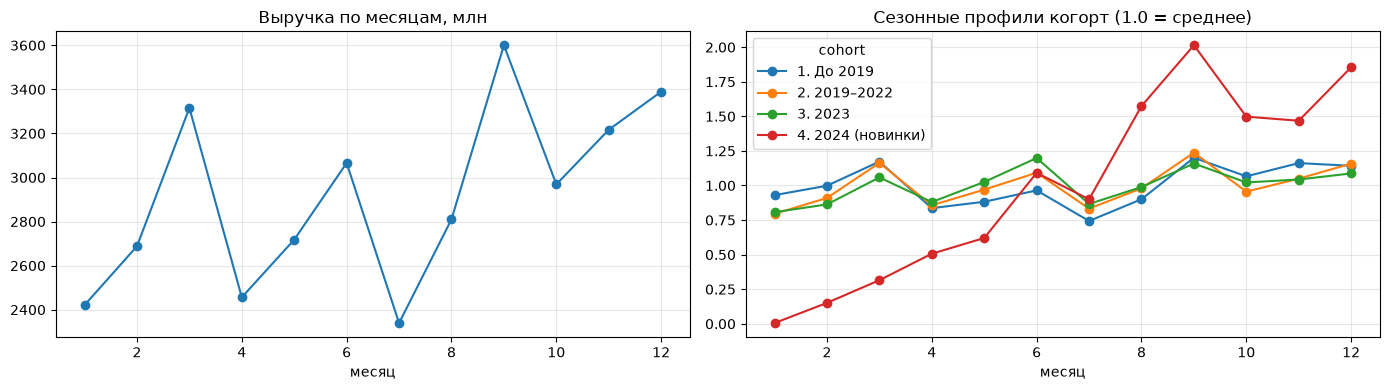

In [11]:
import matplotlib.pyplot as plt

rev_month = df.groupby("sell_month").revenue.sum() / 1e6   # используется ещё дважды ниже
print("выручка по месяцам, млн:\n", rev_month.round(1).to_string())
print("\nсезонный индекс (месяц / среднее):\n", (rev_month / rev_month.mean()).round(3).to_string())

# индекс по позиции месяца в квартале: нужен и здесь, и в прогнозе, и в XYZ
pos_m = pd.Series([(k - 1) % 3 + 1 for k in rev_month.index], index=rev_month.index)
idx_pos = (rev_month / rev_month.mean()).groupby(pos_m).mean()
idx_pos = idx_pos / idx_pos.mean()
print("\nиндекс по позиции месяца в квартале:", {int(k): round(v, 3) for k, v in idx_pos.items()})

mc = df.pivot_table(index="sell_month", columns="cohort", values="revenue", aggfunc="sum") / 1e6
prof = mc / mc.mean()
print("\nнормированные профили по когортам:\n", prof.round(2).to_string())

_, ax = plt.subplots(1, 2, figsize=(14, 4))
rev_month.plot(ax=ax[0], marker="o", title="Выручка по месяцам, млн")
ax[0].set_xlabel("месяц"); ax[0].grid(alpha=.3)
prof.plot(ax=ax[1], marker="o", title="Сезонные профили когорт (1.0 = среднее)")
ax[1].set_xlabel("месяц"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

In [12]:
# альтернативное объяснение: не длиннее ли третьи месяцы кварталов по рабочим дням?
wd = pd.Series({1: 17, 2: 20, 3: 20, 4: 21, 5: 20, 6: 19,
                7: 23, 8: 22, 9: 21, 10: 23, 11: 21, 12: 21})   # произв. календарь РФ, 2024

wdf = pd.DataFrame({"выручка_млн": rev_month.round(1), "раб_дней": wd})
wdf["на_раб_день"] = (wdf.выручка_млн / wdf.раб_дней).round(2)
wdf["поз_в_квартале"] = [(mo - 1) % 3 + 1 for mo in wdf.index]
print(wdf.to_string())

for col in ["выручка_млн", "на_раб_день"]:
    idx = wdf[col] / wdf[col].mean()
    print("\nиндекс «%s» по позиции месяца в квартале:" % col)
    print(idx.groupby(wdf.поз_в_квартале).mean().round(3).to_dict())

    выручка_млн  раб_дней  на_раб_день  поз_в_квартале
1        2420.9        17       142.41               1
2        2688.2        20       134.41               2
3        3315.7        20       165.78               3
4        2456.3        21       116.97               1
5        2718.0        20       135.90               2
6        3065.9        19       161.36               3
7        2339.4        23       101.71               1
8        2810.2        22       127.74               2
9        3600.3        21       171.44               3
10       2968.7        23       129.07               1
11       3216.7        21       153.18               2
12       3389.6        21       161.41               3

индекс «выручка_млн» по позиции месяца в квартале:
{1: 0.873, 2: 0.98, 3: 1.146}

индекс «на_раб_день» по позиции месяца в квартале:
{1: 0.864, 2: 0.972, 3: 1.164}


Главная находка. В каждом квартале третий месяц выше первого, в среднем на 31%. Так во всех четырёх кварталах и во всех группах препаратов.

Четыре альтернативных объяснения я проверил.

| Версия | Как проверял | Что вышло |
|---|---|---|
| к концу квартала продают более дорогое | сравнил индекс в упаковках и в рублях | 0,871 / 0,984 / 1,145 против 0,873 / 0,980 / 1,146, эффект не ценовой |
| третьи месяцы длиннее | среднее число дней по позиции в квартале | 30,50 против 30,75, третьи даже короче |
| в третьих месяцах больше рабочих дней | расчёт выше | в июле 23 рабочих дня и худшая выручка года, в сентябре 21 и лучшая |
| это сезонность потребления | форма профиля | потребовался бы синхронный провал в январе, апреле, июле и октябре |

Остаётся квартальный цикл планирования и стимулирования отгрузок. Механизмов, дающих такую картину, минимум три, и данные не позволяют выбрать между ними:

1. план отдела продаж, менеджеры дожимают отгрузку к закрытию квартала;
2. ретро-бонусы дистрибьюторам за квартальный объём, тогда добирает сам дистрибьютор;
3. бюджетные циклы закупщиков, аптечные сети и госпитальный сегмент закрывают бюджеты поквартально.

Рекомендация от механизма не зависит: выравнивать отгрузки помесячно. А вот к кому идти с этой рекомендацией, зависит, и это первый вопрос к бизнесу.

Сезонность в фарме при этом существует, и она групповая: простуда, аллергия и хроника ведут себя по-разному. Разложить портфель по терапевтическим группам нельзя, в справочнике нет АТХ-классификации. Здесь речь о другом эффекте, о цикле отгрузок.

### 6.1 ABC и XYZ: структура ассортимента

Две независимые оси. ABC делит препараты по вкладу в выручку: группа A даёт первые 80%, B следующие 15%, C оставшиеся 5%. XYZ делит по ровности отгрузок внутри года.

Классические пороги XYZ, 10% и 25% коэффициента вариации, пришли из розницы и здесь не работают: под них попадает один препарат из 355. Причина в том, что отгрузки дистрибьюторам идут партиями, и разброс у отдельного препарата велик сам по себе: медиана коэффициента вариации 0,31.

Квартальный цикл, найденный выше, объясняет лишь малую часть этого разброса: после его снятия медиана падает с 0,31 до 0,29. Значит неровность в основном не от цикла, а от самой природы отгрузок.

Поэтому границы X, Y и Z берём по данным, по третям распределения. Так группы получаются сопоставимыми, а смысл сохраняется: X это самая ровная треть, Z самая рваная.

XYZ считаем только по препаратам с полным годом продаж. У запусков 2024 отгрузки растут с нуля, и любая мера вариации отнесла бы их к Z, но это разгон, а не неровный спрос.

In [13]:
# ABC: вклад препарата в выручку
prod_rev = df.groupby("product_id").revenue.sum().sort_values(ascending=False)
abc = pd.cut(prod_rev.cumsum() / prod_rev.sum(), [0, .80, .95, 1.01], labels=["A", "B", "C"])

# XYZ: ровность отгрузок по месяцам, только препараты с полным годом
by_pm = df.pivot_table(index="product_id", columns="sell_month", values="amount", aggfunc="sum")
full_year = by_pm.notna().sum(axis=1) == 12
by_des = by_pm.div(pd.Series([idx_pos[(k - 1) % 3 + 1] for k in by_pm.columns],
                             index=by_pm.columns), axis=1)          # снимаем квартальный цикл
cv_raw = (by_pm.std(axis=1) / by_pm.mean(axis=1)).where(full_year)
cv = (by_des.std(axis=1) / by_des.mean(axis=1)).where(full_year)
print("коэффициент вариации отгрузок по %d препаратам с полным годом:" % full_year.sum())
print("  до снятия квартального цикла медиана %.2f, после %.2f" % (cv_raw.median(), cv.median()))

x_cut, z_cut = cv.quantile(1/3), cv.quantile(2/3)
xyz = pd.cut(cv, [0, x_cut, z_cut, 99], labels=["X", "Y", "Z"])
print("  границы по третям распределения: X до %.2f, Y до %.2f, Z выше" % (x_cut, z_cut))

assort = pd.DataFrame({"выручка_млн": prod_rev / 1e6, "ABC": abc, "XYZ": xyz,
                       "вариация": cv.round(2),
                       "группа": df.drop_duplicates("product_id").set_index("product_id").cohort,
                       "препарат": df.drop_duplicates("product_id").set_index("product_id").product_name})

tot_rev = prod_rev.sum() / 1e6
g = assort.groupby("ABC", observed=True).agg(препаратов=("выручка_млн", "size"),
                                             выручка_млн=("выручка_млн", "sum"))
g["доля_выручки_%"] = (g.выручка_млн / tot_rev * 100).round(1)
print("\nABC:")
print(g.round(0).to_string())

print("\nматрица ABC × XYZ, препаратов:")
print(pd.crosstab(assort.ABC, assort.XYZ).to_string())

az = assort[(assort.ABC == "A") & (assort.XYZ == "Z")]
cz = assort[(assort.ABC == "C") & (assort.XYZ == "Z")]
print("\nA и Z, крупные с рваными отгрузками: %d препаратов, %.0f млн, %.0f%% выручки"
      % (len(az), az.выручка_млн.sum(), az.выручка_млн.sum() / tot_rev * 100))
print("C и Z, мелкие и рваные: %d препаратов, %.0f млн, %.1f%% выручки"
      % (len(cz), cz.выручка_млн.sum(), cz.выручка_млн.sum() / tot_rev * 100))

коэффициент вариации отгрузок по 355 препаратам с полным годом:
  до снятия квартального цикла медиана 0.31, после 0.29
  границы по третям распределения: X до 0.21, Y до 0.42, Z выше

ABC:
     препаратов  выручка_млн  доля_выручки_%
ABC                                         
A           122      27939.0            80.0
B           105       5277.0            15.0
C           239       1773.0             5.0

матрица ABC × XYZ, препаратов:
XYZ   X   Y   Z
ABC            
A    59  43  20
B    42  36  16
C    18  39  82

A и Z — крупные с рваными отгрузками: 20 препаратов, 3654 млн, 10% выручки
C и Z — мелкие и рваные: 82 препаратов, 593 млн, 1.7% выручки


Группа A из 122 препаратов даёт 80% выручки, группа C из 239 препаратов даёт 5%. Обслуживаются они при этом одинаково.

Практический смысл матрицы в двух её углах. Пересечение A и Z это крупные препараты с рваными отгрузками: именно здесь сбой сильнее всего бьёт по плану, и именно за ними стоит следить помесячно. Пересечение C и Z это мелкие и рваные, кандидаты на пересмотр условий или на вывод из активного портфеля.

ABC пригодится и дальше: он объясняет, почему недобор в разделе 9 ищется по доле в выручке, а не по числу упаковок. Провал по препарату из группы C стоит компании в разы меньше, чем такой же по доле провал в группе A.

## 7. Прогноз на первый квартал 2025

Считаю линейным трендом и сезонным наивным оценщиком. ARIMA и Хольта-Уинтерса не беру, и дело не в простоте.

Сезонной модели нужно минимум два полных цикла сезонности, а здесь один год. Четыре сезонных параметра на четыре квартальные точки дают нулевое число степеней свободы: модель подгонится идеально и не будет значить ничего.

Возражение «но у вас 12 месяцев» тоже не помогает. На каждый календарный месяц приходится ровно одно наблюдение, поэтому сезонность месяца от тренда всё равно не отделить. К тому же на месячном уровне доминирует внутриквартальный цикл из раздела 6, который к потреблению отношения не имеет.

Поэтому беру два простых оценщика, смещённых в разные стороны, и отдаю результат диапазоном. Перед этим проверяю метод на истории: учусь на первых трёх кварталах и предсказываю известный четвёртый.

### 7.1 Проверка на истории

In [14]:
q = df.pivot_table(index="cohort", columns="quarter", values="revenue", aggfunc="sum") / 1e6
print("выручка по когортам и кварталам, млн:\n", q.round(1).to_string(), "\n")

def fit_ols(y):
    """линейный тренд по точкам y; возвращает (intercept, slope)"""
    t = np.arange(1, len(y) + 1)
    b, a = np.polyfit(t, y, 1)
    return a, b

rows = []
for c in q.index:
    y = q.loc[c].values
    a, b = fit_ols(y[:3])                  # учимся только на Q1-Q3
    pred = a + b * 4
    rows.append([c, y[3], pred, (pred - y[3]) / y[3] * 100])

bt = pd.DataFrame(rows, columns=["когорта", "факт Q4", "прогноз Q4", "ошибка %"]).set_index("когорта")
print(bt.round(1).to_string())

# сравнение: сумма когорт против одной регрессии на всю компанию
tot = q.sum().values
a, b = fit_ols(tot[:3])
pred_total = a + b * 4
pred_cohorts = sum(r[2] for r in rows)

print("\nфакт Q4:                  %8.1f" % tot[3])
print("одна регрессия по итогу:  %8.1f  (ошибка %+.1f%%)" % (pred_total, (pred_total-tot[3])/tot[3]*100))
print("сумма прогнозов когорт:   %8.1f  (ошибка %+.1f%%)" % (pred_cohorts, (pred_cohorts-tot[3])/tot[3]*100))

print("\nсредняя абсолютная ошибка по группам: %.1f%%" % bt["ошибка %"].abs().mean())

выручка по когортам и кварталам, млн:
 quarter                 1       2       3       4
cohort                                           
1. До 2019         3551.1  3072.0  3257.0  3859.1
2. 2019–2022       4129.3  4202.5  4390.1  4553.6
3. 2023             711.0   808.8   785.4   821.4
4. 2024 (новинки)    33.4   156.9   317.5   340.9 

                   факт Q4  прогноз Q4  ошибка %
когорта                                         
1. До 2019          3859.1      2999.3     -22.3
2. 2019–2022        4553.6      4501.5      -1.1
3. 2023              821.4       842.8       2.6
4. 2024 (новинки)    340.9       453.3      33.0

факт Q4:                    9575.0
одна регрессия по итогу:    8796.9  (ошибка -8.1%)
сумма прогнозов когорт:     8796.9  (ошибка -8.1%)

средняя абсолютная ошибка по группам: 14.7%


Зрелые группы тренд предсказывает хорошо: ошибка −1,1% по группе 2019–2022 и +2,6% по 2023 году.

Группа до 2019 промахивается на −22,3%, и это не вина метода. Её ряд идёт 3551, 3072, 3257, 3859. На первых трёх точках наклон отрицательный, модель честно продолжает вниз, а четвёртый квартал выстреливает вверх. Предсказать сезонный пик по трём точкам нельзя ничем.

Запуски 2024 дают +33%. Их ряд 33, 157, 318, 341 насыщается, прирост четвёртого квартала к третьему уже всего 7%, а линейная протяжка тянет по старому наклону.

Сумма прогнозов по группам совпала с одной регрессией по итогу до десятой доли. Это не совпадение: МНК линеен, поэтому сумма прогнозов по частям тождественно равна прогнозу по сумме. Декомпозиция окупается только тогда, когда к разным группам применяются разные методы.

### 7.2 Прогноз по группам

Зрелым группам считаю тренд и оценка по одноимённому кварталу. Запускам 2024 линейный тренд не годится, вместо него затухающее продолжение разгона.

In [15]:
# тренд считаем той же функцией fit_ols, что в проверку на историие выше
fc = {}
for c in q.index:
    y = q.loc[c].values
    a, b = fit_ols(y)                    # тренд по всем 4 кварталам
    g = 4 * b / y.mean()             # подразумеваемый годовой рост
    fc[c] = {"тренд, 1 кв. 2025": a + b * 5,      # экстраполяция на следующую точку ряда
             "по одноимённому кварталу": y[0] * (1 + g),   # факт 1 кв. 2024 × годовой рост
             "годовой рост, %": g * 100}

fcdf = pd.DataFrame(fc).T

# новинки: затухающее продолжение разгона вместо линейного тренда
r = q.loc["4. 2024 (новинки)"]
damped = r[4] * (r[4] / r[3]) ** 0.5
fcdf["метод"] = "тренд и по одноимённому кварталу"
fcdf.loc["4. 2024 (новинки)", ["тренд, 1 кв. 2025", "по одноимённому кварталу"]] = damped
# для этой группы линейный тренд не применялся, поэтому «годовой рост» из МНК не используется
fcdf.loc["4. 2024 (новинки)", "годовой рост, %"] = np.nan
fcdf.loc["4. 2024 (новинки)", "метод"] = "затухающий разгон"

print(fcdf.round(1).to_string())

lo = fcdf[["тренд, 1 кв. 2025", "по одноимённому кварталу"]].min(axis=1).sum()
hi = fcdf[["тренд, 1 кв. 2025", "по одноимённому кварталу"]].max(axis=1).sum()
mid = fcdf[["тренд, 1 кв. 2025", "по одноимённому кварталу"]].mean(axis=1).sum()

print("\nПРОГНОЗ НА 1 КВ. 2025, млн руб")
print("  пессимистичный: %7.0f  (%+.1f%% к 1 кв. 2024)" % (lo,  (lo/q[1].sum()-1)*100))
print("  базовый:        %7.0f  (%+.1f%% к 1 кв. 2024)" % (mid, (mid/q[1].sum()-1)*100))
print("  оптимистичный:  %7.0f  (%+.1f%% к 1 кв. 2024)" % (hi,  (hi/q[1].sum()-1)*100))
print("\nсправочно: 1 кв. 2024 = %.0f, 4 кв. 2024 = %.0f" % (q[1].sum(), q[4].sum()))

                   тренд, Q1'25  по одноимённому кварталу  годовой рост, %                             метод
1. До 2019               3712.1                    4009.7             12.9  тренд и по одноимённому кварталу
2. 2019–2022             4684.0                    4687.8             13.5  тренд и по одноимённому кварталу
3. 2023                   858.6                     822.9             15.7  тренд и по одноимённому кварталу
4. 2024 (новинки)         353.3                     353.3              NaN                 затухающий разгон

ПРОГНОЗ Q1 2025, млн руб
  пессимистичный:    9572  (+13.6% к Q1'24)
  базовый:           9741  (+15.6% к Q1'24)
  оптимистичный:     9909  (+17.6% к Q1'24)

справочно: Q1'24 = 8425, Q4'24 = 9575


In [16]:
# сценарий стагнации: база не растёт, разгоняются только новинки
stagn = q[1].sum() - q.loc["4. 2024 (новинки)", 1] + fcdf.loc["4. 2024 (новинки)", "тренд, 1 кв. 2025"]
print("сценарий стагнации: %.0f млн (%+.1f%% к 1 кв. 2024)" % (stagn, (stagn/q[1].sum()-1)*100))

сценарий стагнации: 8745 млн (+3.8% к Q1'24)


### 7.3 Проверка прогноза второй моделью

Квартальная модель опирается на 4 точки и проверена одним предсказанием четвёртого квартала. Данных при этом 12 месячных точек, и внутриквартальный цикл имеет период три месяца, значит на них укладывается четыре полных цикла, и сезонность можно оценить, а не подогнать. Заодно появляется скользящая проверка: шесть предсказаний вне выборки вместо одного.

In [17]:
# Снимаем внутриквартальный цикл, строим тренд по 12 очищенным точкам, возвращаем цикл.
# индекс по позиции месяца посчитан в разделе 6
des = rev_month / pos_m.map(idx_pos)
b_m, a_m = np.polyfit(np.arange(1, 13), des, 1)
fc_month = [(a_m + b_m * (13 + k)) * idx_pos[(12 + k) % 3 + 1] for k in range(3)]
fc_q1_month = sum(fc_month)
print("прогноз месяцев 13-15:", [round(x) for x in fc_month])
print("1 кв. 2025: месячная модель %.0f млн, квартальная %.0f млн, расхождение %.1f%%"
      % (fc_q1_month, mid, (fc_q1_month / mid - 1) * 100))

# скользящая проверка: учимся на месяцах 1..k, предсказываем k+1
rows_bt = []
for k in range(6, 12):
    bb, aa = np.polyfit(np.arange(1, k + 1), des[:k], 1)
    pred = (aa + bb * (k + 1)) * idx_pos[pos_m.iloc[k]]
    fact = rev_month.iloc[k]
    rows_bt.append((k + 1, fact, pred, (pred - fact) / fact * 100))

bt_month = pd.DataFrame(rows_bt, columns=["месяц", "факт", "прогноз", "ошибка %"]).set_index("месяц")
mape_month = bt_month["ошибка %"].abs().mean()
print("\nскользящая проверка вне выборки:")
print(bt_month.round(1).to_string())
print("средняя ошибка по шести проверкам: %.1f%%" % mape_month)

прогноз месяцев 13-15: [2792, 3176, 3764]
Q1 2025: месячная модель 9731 млн, квартальная 9741 млн, расхождение -0.1%

скользящая проверка вне выборки:
         факт  прогноз  ошибка %
месяц                           
7      2339.4   2384.0       1.9
8      2810.2   2634.1      -6.3
9      3600.3   3161.8     -12.2
10     2968.7   2553.2     -14.0
11     3216.7   3073.5      -4.5
12     3389.6   3709.7       9.4
средняя ошибка по шести проверкам: 8.0%


Две модели дают 9 731 и 9 741 млн, расхождение 0,1%. Прогноз устойчив к смене метода, и это сильнее, чем один результат без альтернативы.

Скользящая проверка даёт средняя ошибка 8,0% по шести предсказаниям вне выборки. Теперь точность прогноза измерена, а не просто оговорена.

## 8. Эффективность территорий

In [18]:
tot = df.groupby("branch").agg(rev=("revenue","sum"), packs=("amount","sum"),
                               products=("product_id","nunique"), regions=("region","nunique"))
q_branch = df.pivot_table(index="branch", columns="quarter",
                          values="revenue", aggfunc="sum")   # используется ещё в двух ячейках ниже
new = df[df.cohort == "4. 2024 (новинки)"].groupby("branch").revenue.sum()

b = pd.DataFrame({
    "выручка, млн":     tot.rev / 1e6,
    "доля рынка, %":    tot.rev / tot.rev.sum() * 100,
    "ср. цена упак, ₽": tot.rev / tot.packs,
    "Q4/Q1":            q_branch[4] / q_branch[1],
    "новинки, %":       new / tot.rev * 100,
    "препаратов":       tot.products,
    "регионов":         tot.regions,
}).sort_values("выручка, млн", ascending=False)

print(b.round(2).to_string())
print("\nразмах 4 кв. к 1 кв.: от %.2f до %.2f" % (b["Q4/Q1"].min(), b["Q4/Q1"].max()))

                                   выручка, млн  доля рынка, %  ср. цена упак, ₽  Q4/Q1  новинки, %  препаратов  регионов
branch                                                                                                                   
Северо-Запад России                     4385.26          12.53            201.25   1.18        2.41         449        10
Западная Сибирь                         3634.16          10.39            199.59   1.10        2.34         450        10
Восточная Сибирь и Дальний Восток       3603.35          10.30            206.20   1.17        1.52         427        12
Юг России                               3540.79          10.12            203.21   1.16        2.78         441         9
Московская область                      3269.19           9.34            198.45   1.17        1.83         437         8
Центр                                   3242.23           9.27            200.42   1.05        1.91         441        10
Урал                    

In [19]:
# Насколько рост территории держится на запусках 2024?
# Считаем Q4/Q1 с новинками и без них: разница показывает, что маскируют новинки.
full = q_branch          # тот же pivot, посчитан в ячейке выше
base = df_base.pivot_table(index="branch", columns="quarter",
                           values="revenue", aggfunc="sum")

mask = pd.DataFrame({
    "Q4/Q1 всего":       full[4] / full[1],
    "Q4/Q1 без новинок": base[4] / base[1],
    "доля новинок, %":   df[df.cohort == "4. 2024 (новинки)"].groupby("branch").revenue.sum()
                         / df.groupby("branch").revenue.sum() * 100,
})
mask["просадка"] = mask["Q4/Q1 без новинок"] - mask["Q4/Q1 всего"]
print(mask.round(3).sort_values("Q4/Q1 всего").to_string())

print("\nкорреляция доли новинок с величиной просадки: %.2f"
      % mask["доля новинок, %"].corr(-mask["просадка"]))
print("худший по базовому портфелю: %s (%.3f)"
      % (mask["Q4/Q1 без новинок"].idxmin(), mask["Q4/Q1 без новинок"].min()))

                                   Q4/Q1 всего  Q4/Q1 без новинок  доля новинок, %  просадка
branch                                                                                      
Центр                                    1.047              1.023            1.907    -0.024
Урал                                     1.082              1.021            4.113    -0.061
Западная Сибирь                          1.097              1.064            2.337    -0.033
Нижнее Поволжье                          1.121              1.065            3.468    -0.056
Верхнее Поволжье                         1.136              1.094            2.612    -0.041
Юг России                                1.163              1.117            2.782    -0.046
Московская область                       1.166              1.140            1.826    -0.026
Москва                                   1.172              1.145            1.735    -0.027
Восточная Сибирь и Дальний Восток        1.172              1.152     

Итоговый рост территории и рост её основного портфеля это разные вещи, и расходятся они тем сильнее, чем больше доля новых препаратов. Корреляция 0,98.

Сильнее всех расхождение у Урала. По итогу он растёт на 8,2%, но 4,1% его выручки это запуски 2024 года, растущие кратно. Без них рост 2,1%, просадка 0,061, максимальная в компании.

Практический смысл: итоговая цифра Урала выглядит лучше, чем состояние его основного портфеля. Насколько он при этом хуже или лучше Центра, точечные оценки сказать не позволяют, это видно по интервалам ниже.

### 8.1 Отставание территории: факт или шум?

Мы сравнивали точечные оценки роста с медианой, ничего не зная о разбросе. Доверительные интервалы считаем повторными выборками. Единица выборки: пара «регион и препарат» целиком, со всеми кварталами. Если тасовать отдельные кварталы, рвётся связь между первым и четвёртым кварталом одной пары, и интервал раздувается вдвое.

In [20]:
def boot_growth(sub, n=600, seed=7):
    """95%-интервал для Q4/Q1: берём повторные выборки пары «регион и препарат» со всеми кварталами"""
    piv = sub.pivot_table(index=["region", "product_id"], columns="quarter",
                          values="revenue", aggfunc="sum").fillna(0)
    v1 = piv.get(1, pd.Series(0.0, index=piv.index)).values
    v4 = piv.get(4, pd.Series(0.0, index=piv.index)).values
    rng = np.random.default_rng(seed)
    N, out = len(piv), []
    for _ in range(n):
        ix = rng.integers(0, N, N)
        s1 = v1[ix].sum()
        if s1 > 0:
            out.append(v4[ix].sum() / s1)
    return np.percentile(out, [2.5, 97.5]), v4.sum() / v1.sum()

med_all = (q_branch[4] / q_branch[1]).median()
rows_ci = []
for br in q_branch.index:
    (lo_ci, hi_ci), pt = boot_growth(df[df.branch == br])
    rows_ci.append((br, pt, lo_ci, hi_ci,
                    "ниже медианы" if hi_ci < med_all else
                    "выше медианы" if lo_ci > med_all else "не отличается"))

ci = pd.DataFrame(rows_ci, columns=["территория", "Q4/Q1", "низ 95%", "верх 95%",
                                    "против медианы"]).set_index("территория")
print("медиана роста по компании: %.3f\n" % med_all)
print(ci.round(3).sort_values("Q4/Q1").to_string())

print("\nто же по основному портфелю, без запусков 2024:")
qb_base = df_base.pivot_table(index="branch", columns="quarter", values="revenue", aggfunc="sum")
med_base = (qb_base[4] / qb_base[1]).median()
base_ci = {}
for br in ("Урал", "Центр", "Западная Сибирь"):
    (lo_ci, hi_ci), pt = boot_growth(df_base[df_base.branch == br])
    base_ci[br] = (pt, lo_ci, hi_ci)
    print("  %-18s %.3f  [%.3f; %.3f]" % (br, pt, lo_ci, hi_ci))
print("  медиана по основному портфелю: %.3f" % med_base)
print("\nинтервалы Урала и Центра перекрываются, значит по основному портфелю")
print("они неразличимы между собой, хотя оба ниже медианы")

медиана роста по компании: 1.163

                                   Q4/Q1  низ 95%  верх 95% против медианы
территория                                                                
Центр                              1.047    1.013     1.078   ниже медианы
Урал                               1.082    1.036     1.129   ниже медианы
Западная Сибирь                    1.097    1.053     1.141   ниже медианы
Нижнее Поволжье                    1.121    1.066     1.180  не отличается
Верхнее Поволжье                   1.136    1.090     1.175  не отличается
Юг России                          1.163    1.112     1.213  не отличается
Московская область                 1.166    1.129     1.200  не отличается
Москва                             1.172    1.124     1.227  не отличается
Восточная Сибирь и Дальний Восток  1.172    1.126     1.223  не отличается
Северо-Запад России                1.176    1.121     1.246  не отличается
Северный Кавказ                    1.182    1.109     1.251  не от

**Что изменилось после проверки.**

Три отстающие территории подтвердились: у Центра, Урала и Западной Сибири верхняя граница интервала лежит ниже медианы 1,163.

Нижнее Поволжье в медиану попадает, интервал [1,066; 1,180]. Значит его 116 млн «недобора роста» статистически не обоснованы, и в списке отстающих ему места нет.

По основному портфелю Урал 1,021 [0,980; 1,061] и Центр 1,023 [0,993; 1,055]. Интервалы перекрываются почти полностью, поэтому разница в 0,002 ничего не значит: **утверждать, что Урал хуже Центра, нельзя**. Оба ниже медианы, и это всё, что показывают данные.

Что остаётся верным про Урал: у него максимальная в компании просадка при исключении запусков 2024, она равна 0,061. То есть итоговая цифра 1,082 выглядит лучше, чем состояние основного портфеля. Это факт о разрыве между двумя показателями, а не о месте в рейтинге.

## 9. Точки роста

Три рычага считаю независимо. Складывать их в один итог нельзя, они пересекаются: рост доли новинок сам по себе поднимает и среднюю цену упаковки.

In [21]:
med_growth = (q_branch[4] / q_branch[1]).median()

lever = pd.DataFrame(index=q_branch.index)
# 1. Динамика: сколько недобрал Q4, если бы рос как медиана
lever["недобор роста, млн/год"] = ((q_branch[1] * med_growth - q_branch[4]).clip(lower=0)) / 1e6
lever["недобор роста, млн/год"] *= 4   # квартальный недобор → годовой масштаб

# 2. Новинки: доведение доли до средней по компании
rev_b = df.groupby("branch").revenue.sum()
new_b = df[df.cohort == "4. 2024 (новинки)"].groupby("branch").revenue.sum()
mean_new_share = new_b.sum() / rev_b.sum()
lever["потенциал по запускам, млн"] = ((mean_new_share * rev_b - new_b).clip(lower=0)) / 1e6

# 3. Микс: доведение средней цены упаковки до средней по компании
packs_b = df.groupby("branch").amount.sum()
price_b = rev_b / packs_b
mean_price = rev_b.sum() / packs_b.sum()
lever["потенциал по цене упаковки, млн"] = ((mean_price - price_b).clip(lower=0) * packs_b) / 1e6

print(lever.round(0).sort_values("недобор роста, млн/год", ascending=False).to_string())
print("\nИТОГО по рычагам, млн:\n", lever.sum().round(0).to_string())

                                   недобор роста, млн/год  потенциал по запускам, млн  потенциал по цене упаковки, млн
branch                                                                                                                
Центр                                               389.0                        17.0                              0.0
Урал                                                247.0                         0.0                              0.0
Западная Сибирь                                     234.0                         3.0                             11.0
Нижнее Поволжье                                     116.0                         0.0                            227.0
Верхнее Поволжье                                     66.0                         0.0                              0.0
Восточная Сибирь и Дальний Восток                     0.0                        33.0                              0.0
Москва                                          

In [22]:
# Разрыв средней цены Нижнего Поволжья: держится на нескольких позициях или размазан?
npv = df[df.branch == "Нижнее Поволжье"]
oth = df[df.branch != "Нижнее Поволжье"]
sh_np = npv.groupby("product_id").amount.sum() / npv.amount.sum()
sh_ot = oth.groupby("product_id").amount.sum() / oth.amount.sum()
prices = df.drop_duplicates("product_id").set_index("product_id").price

mix = pd.DataFrame({"доля_НП": sh_np, "доля_остальных": sh_ot, "цена": prices}).fillna(0)
mix["вклад_в_разрыв"] = (mix.доля_НП - mix.доля_остальных) * mix.цена

neg = mix[mix.вклад_в_разрыв < 0].вклад_в_разрыв.sum()
pos = mix[mix.вклад_в_разрыв > 0].вклад_в_разрыв.sum()
top2 = mix.вклад_в_разрыв.nsmallest(2).sum()

print("разрыв средней цены упаковки: %.2f руб" % mix.вклад_в_разрыв.sum())
print("сумма отрицательных вкладов: %.2f руб | положительных: +%.2f руб" % (neg, pos))
print("две крупнейшие позиции дают %.2f руб, это %.0f%% отрицательных вкладов"
      % (top2, top2 / neg * 100))
print("позиций с отрицательным вкладом: %d из %d" % ((mix.вклад_в_разрыв < 0).sum(), len(mix)))
print("\nдесять худших позиций:")
print(mix.nsmallest(10, "вклад_в_разрыв").round(4).to_string())

разрыв средней цены упаковки: -16.35 руб
сумма отрицательных вкладов: -50.78 руб | положительных: +34.43 руб
две крупнейшие позиции дают -4.50 руб — это 9% отрицательных вкладов
позиций с отрицательным вкладом: 326 из 466

десять худших позиций:
            доля_НП  доля_остальных    цена  вклад_в_разрыв
product_id                                                 
28850        0.0029          0.0166  236.25         -3.2505
72           0.0079          0.0135  223.37         -1.2494
28743        0.0007          0.0029  463.75         -1.0447
28726        0.0014          0.0029  656.25         -1.0291
28672        0.0091          0.0133  236.25         -0.9994
28727        0.0013          0.0028  656.25         -0.9893
28883        0.0004          0.0033  306.25         -0.8946
29413        0.0005          0.0017  779.64         -0.8640
28867        0.0011          0.0025  551.25         -0.7865
28862        0.0051          0.0085  201.25         -0.6821


Разрыв в 16,35 руб на упаковку складывается из 50,78 руб отрицательных вкладов и 34,43 руб положительных. Две крупнейшие позиции дают 4,50 руб, то есть **9% отрицательных вкладов**, а всего позиций с отрицательным вкладом 326 из 466.

Значит перекос широкий, а не сосредоточен на нескольких препаратах. Территория систематически продаёт больше дешёвого и меньше дорогого почти по всему портфелю.

Это меняет рекомендацию. Работа с двумя-тремя позициями разрыв не закроет, речь про структуру продаж целиком. И причина по этим данным неизвестна: платёжеспособность региона, локальная конкуренция по дорогим позициям, структура плательщиков или работа с дорогим портфелем. Различить их по этим данным нечем.

### 9.1 Недобор до типичной доли

Идея простая. Если препарат в девяти территориях занимает около 0,5% выручки, а в десятой 0,02%, то рынок для него есть, а продаж нет. Размер недобора считаю как разницу до типичной доли, умноженную на размер территории.

Препараты, которые продаются меньше чем в 8 территориях из 11, из расчёта убираю: типичная доля по одному-двум наблюдениям недостоверна.

In [23]:
rev_bp = df.groupby(["branch", "product_id"]).revenue.sum().unstack(fill_value=0)
share  = rev_bp.div(rev_bp.sum(axis=1), axis=0)   # доля препарата в выручке филиала

# типичная доля препарата там, где он реально продаётся
typical = share[share > 0].median()

# недобор в рублях: насколько филиал не дотягивает до типичной доли
gap = (typical - share).clip(lower=0).mul(rev_bp.sum(axis=1), axis=0)
gap = gap.where(share < typical * 0.25)           # оставляем только явные расхождения

# отсекаем препараты с узкой географией: медиана по 1-3 филиалам недостоверна
coverage = (rev_bp > 0).sum(axis=0)
gap = gap.loc[:, coverage >= 8]

top = (gap.stack().sort_values(ascending=False).head(20) / 1e6).round(1)
top.index.names = ["branch", "product_id"]
names = df.drop_duplicates("product_id").set_index("product_id").product_name
print(top.rename("недобор, млн").reset_index().assign(
      препарат=lambda d: d.product_id.map(names)).to_string(index=False))

print("\nпар с недобором (доля ниже 25%% типичной): %d" % gap.notna().sum().sum())
print("суммарный недобор: %.0f млн" % (gap.sum().sum() / 1e6))

by_br = (gap.sum(axis=1) / 1e6).sort_values(ascending=False)
print("\nнедобор по территориям, млн:")
print(by_br[by_br > 0].round(1).to_string())
print("территорий с недобором: %d из %d | топ-3 дают %.0f%% суммы"
      % ((by_br > 0).sum(), len(by_br), by_br.nlargest(3).sum() / by_br.sum() * 100))

          branch  product_id  недобор, млн     препарат
            Урал       28743          16.7 Препарат 146
 Нижнее Поволжье       28743          15.7 Препарат 146
 Нижнее Поволжье       28883          12.4 Препарат 239
            Урал       29256          12.4 Препарат 300
            Урал       28883          12.3 Препарат 239
Верхнее Поволжье       28883          10.1 Препарат 239
          Москва       28704           9.6 Препарат 128
          Москва       28710           9.0 Препарат 126
          Москва       29358           8.5 Препарат 342
 Нижнее Поволжье       29130           8.0 Препарат 199
          Москва       28880           5.9 Препарат 278
 Нижнее Поволжье       28768           5.8  Препарат 97
 Нижнее Поволжье       28966           5.1 Препарат 306
 Нижнее Поволжье       29221           4.8 Препарат 305
          Москва       28874           4.6 Препарат 316
 Нижнее Поволжье       28882           4.2 Препарат 238
            Урал       28820           4.2 Препа

Метод сравнивает долю препарата в выручке территории с типичной долей по другим территориям. Отсюда законное возражение: рынки разные, и низкая доля может быть особенностью региона, а не недоработкой. Три проверки ниже показывают, где метод работает, а где нет.

In [24]:
# 1. Похожи ли ассортиментные профили территорий между собой?
cm = share.T.corr(method="spearman")
pairs_corr = cm.values[np.triu_indices_from(cm, 1)]
print("корреляция профилей территорий: минимум %.2f, медиана %.2f, максимум %.2f"
      % (pairs_corr.min(), np.median(pairs_corr), pairs_corr.max()))

# 2. Порог 0,25: это выброс или обычный разброс?
ratio = (share / typical).replace([np.inf, -np.inf], np.nan).loc[:, coverage >= 8]
rs = ratio.stack().dropna()
print("\nотношение доли к типичной, квантили:")
print("  5%%: %.2f | 10%%: %.2f | 25%%: %.2f | 50%%: %.2f | 75%%: %.2f"
      % tuple(rs.quantile(q) for q in (.05, .10, .25, .50, .75)))
print("ниже порога 0,25: %d пар, это %.1f%% всех пар" % ((rs < 0.25).sum(), (rs < 0.25).mean() * 100))

# 3. Насколько устойчива доля самого препарата по территориям?
#    Если она и так скачет, «типичная доля» становится слабым ориентиром.
sh_pos = share.loc[:, coverage >= 8].where(lambda x: x > 0)
disp = (sh_pos.quantile(.75) - sh_pos.quantile(.25)) / sh_pos.median()
print("\nразброс доли по препаратам (межквартильный размах к медиане): медиана %.2f" % disp.median())

print("\nчувствительность результата к порогу устойчивости:")
for thr in (.25, .50, .75, 1.00):        # не q: имя q занято таблицей «группа на квартал»
    keep = disp[disp <= disp.quantile(thr)].index
    print("  препараты с разбросом до %3.0f%% квантиля: %3d пар, %5.0f млн"
          % (thr * 100, gap[keep].notna().sum().sum(), gap[keep].stack().sum() / 1e6))

stable = disp[disp <= disp.median()].index
core = gap[stable].stack()
core_pairs, core_sum = gap[stable].notna().sum().sum(), core.sum() / 1e6
print("\nустойчивое ядро: %d пар на %.0f млн из %d пар на %.0f млн"
      % (core_pairs, core_sum, gap.notna().sum().sum(), gap.stack().sum() / 1e6))

корреляция профилей территорий: минимум 0.88, медиана 0.93, максимум 0.97

отношение доли к типичной, квантили:
  5%: 0.35 | 10%: 0.48 | 25%: 0.73 | 50%: 1.00 | 75%: 1.33
ниже порога 0,25: 109 пар, это 2.5% всех пар

разброс доли по препаратам (межквартильный размах к медиане): медиана 0.59

чувствительность результата к порогу устойчивости:
  препараты с разбросом до  25% квантиля:   1 пар,     9 млн
  препараты с разбросом до  50% квантиля:  12 пар,    55 млн
  препараты с разбросом до  75% квантиля:  39 пар,   170 млн
  препараты с разбросом до 100% квантиля: 109 пар,   222 млн

устойчивое ядро: 12 пар на 55 млн из 109 пар на 222 млн


In [25]:
# Кластерные случаи: фильтр разброса их отбрасывает ошибочно.
# Если препарат провалился сразу в нескольких смежных территориях, сам провал
# и раздувает разброс. Проверяем: убираем провальные территории и считаем разброс заново.
print("проверка кластерных случаев\n")
for pid in (28743, 28883):
    col = (share[pid] / typical[pid]).sort_values()
    low = col[col < 0.25].index.tolist()
    rest = share[pid].drop(low)
    d_all = (share[pid].quantile(.75) - share[pid].quantile(.25)) / share[pid].median()
    d_rest = (rest.quantile(.75) - rest.quantile(.25)) / rest.median()
    print("препарат %d: провал в %d территориях, %s" % (pid, len(low), ", ".join(low)))
    print("  доля к типичной у них: %s" % [round(float(v), 2) for v in col[col < 0.25].values])
    print("  разброс доли: по всем территориям %.2f, без провальных %.2f (медиана по портфелю %.2f)"
          % (d_all, d_rest, disp.median()))

проверка кластерных случаев

препарат 28743: провал в 2 территориях — Нижнее Поволжье, Урал
  доля к типичной у них: [0.24, 0.25]
  разброс доли: по всем территориям 0.60, без провальных 0.50 (медиана по портфелю 0.59)
препарат 28883: провал в 3 территориях — Нижнее Поволжье, Верхнее Поволжье, Урал
  доля к типичной у них: [0.13, 0.19, 0.21]
  разброс доли: по всем территориям 0.88, без провальных 0.45 (медиана по портфелю 0.59)


**Что показали проверки.**

Профили территорий похожи: корреляция ассортиментных долей по всем 55 парам от 0,88 до 0,97, медиана 0,93. Значит на уровне портфеля рынки не «разные»: территории продают примерно одно и то же в примерно тех же пропорциях.

Порог 0,25 отсекает выбросы, а не обычный разброс. Пятипроцентный квантиль отношения к типичной доле равен 0,35, то есть под порог попадает 2,5% пар, это тонкий хвост.

А вот доля отдельного препарата по территориям гуляет заметно: межквартильный размах к медиане составляет 0,59. Для таких препаратов «типичная доля» слабый ориентир, и возражение про разные рынки работает.

Отсюда двухуровневая оценка. Если оставить только препараты со стабильной долей, где типичное значение осмысленно, остаётся **12 пар на 55 млн руб**. Вся сумма в **222 млн по 109 парам** это верхняя граница, и часть её объясняется различием рынков. Чувствительность видна в таблице: 9 млн на самом строгом пороге, 55, 170 и 222 млн дальше.

**Кластерные случаи фильтр отбрасывает ошибочно.** Он рассчитан на одиночный выброс: если препарат провалился сразу в нескольких смежных территориях, сам провал раздувает разброс, и препарат отсеивается. У 28883 разброс без провальных территорий падает с 0,88 до 0,45, у 28743 с 0,60 до 0,50: у остальных территорий доля стабильна. Значит эти два случая остаются в силе, причём 28883 выглядит убедительнее: там доля к типичной 0,13, 0,19 и 0,21, тогда как у 28743 два значения стоят прямо на пороге, 0,24 и 0,25.

## 10. Выгрузка данных

Python отдаёт плоские таблицы, из которых дальше собирается дашборд.

In [26]:
# --- куб для сводных таблиц ---
cube = (df.groupby(["branch","region","product_id","product_name","cohort","quarter"])
          .agg(упаковок=("amount","sum"), выручка=("revenue","sum"))
          .reset_index())

# --- KPI ---
rev_year   = df.revenue.sum()
packs_year = df.amount.sum()
base_q     = df_base.groupby("quarter").revenue.sum()

kpi = pd.DataFrame({
    "показатель": [
        "Выручка за 2024, млн ₽", "Упаковок за 2024, млн", "Средняя цена упаковки, ₽",
        "Препаратов в продаже", "Филиалов", "Регионов",
        "Рост 4 кв. к 1 кв., %", "Рост 4 кв. к 1 кв. без новинок 2024, %",
        "Доля новинок 2024 в выручке, %",
        "Прогноз на 1 кв. 2025, базовый, млн ₽", "Прогноз на 1 кв. 2025, разброс методов, млн ₽",
    ],
    "значение": [
        rev_year/1e6, packs_year/1e6, rev_year/packs_year,
        df.product_id.nunique(), df.branch.nunique(), df.region.nunique(),
        (q[4].sum()/q[1].sum()-1)*100, (base_q[4]/base_q[1]-1)*100,
        df[df.cohort=="4. 2024 (новинки)"].revenue.sum()/rev_year*100,
        mid, np.nan,
    ],
    "комментарий": [
        "", "", "", "", "11 филиалов, 4 региона делятся между двумя", "",
        "", "новинки 2024 исключены, это рост базового портфеля",
        "79 препаратов, вышедших в 2024",
        "среднее двух оценщиков: тренд и по одноимённому кварталу",
        f"{lo:.0f} – {hi:.0f}; сценарий стагнации {stagn:.0f}",
    ],
})

# --- динамика по месяцам ---
dyn = (df.groupby("sell_month")
         .agg(выручка_млн=("revenue", lambda s: s.sum()/1e6),
              упаковок_тыс=("amount", lambda s: s.sum()/1e3)))
dyn["сезонный_индекс"] = dyn.выручка_млн / dyn.выручка_млн.mean()
dyn["позиция_в_квартале"] = [(m-1) % 3 + 1 for m in dyn.index]
dyn.index.name = "месяц"

# --- прогноз ---
forecast = fcdf.copy()
forecast.loc["ИТОГО"] = [fcdf["тренд, 1 кв. 2025"].sum(), fcdf["по одноимённому кварталу"].sum(),
                         np.nan, "сумма по группам"]

print("куб собран:", cube.shape[0], "строк")

куб собран: 126399 строк


## 11. Сводка чисел для выводов

Каждое число, которое попадает в выводы и рекомендации, считается здесь. Если в тексте появится цифра, которой нет в этой таблице, значит текст разошёлся с расчётом.

Таблица уходит в файл отдельным листом «Ключевые_числа», чтобы проверяющий мог сверить любую цифру из отчёта, не открывая Python.

In [27]:
# Все числа, которые цитируются в выводах и рекомендациях, собраны здесь.
# Если какое-то число в тексте не совпадёт с этой таблицей, значит текст устарел.
kf = []
def add(name, val, unit=""):
    kf.append((name, round(float(val), 3), unit))

rev, pk = df.revenue.sum(), df.amount.sum()
add("Выручка за год", rev / 1e6, "млн руб")
add("Упаковок за год", pk / 1e6, "млн шт")
add("Средняя цена упаковки", rev / pk, "руб")
add("Препаратов в продаже", df.product_id.nunique(), "шт")
add("Группа A: препаратов", (assort.ABC == "A").sum(), "дают 80% выручки")
add("Группа C: препаратов", (assort.ABC == "C").sum(), "дают 5% выручки")
add("Крупные с рваными отгрузками (A и Z)", ((assort.ABC == "A") & (assort.XYZ == "Z")).sum(), "препаратов")
add("Их доля в выручке", az.выручка_млн.sum() / (prod_rev.sum() / 1e6) * 100, "%")
add("Сбытовых территорий", df.branch.nunique(), "шт")
add("Регионов", df.region.nunique(), "шт")

qs = df.groupby("quarter").revenue.sum()
add("Рост 4 кв. к 1 кв.", (qs[4] / qs[1] - 1) * 100, "%")
qb0 = df[df.cohort != "4. 2024 (новинки)"].groupby("quarter").revenue.sum()
add("Рост 4 кв. к 1 кв. без запусков 2024", (qb0[4] / qb0[1] - 1) * 100, "%")

nw = df[df.cohort == "4. 2024 (новинки)"]
nwq = nw.groupby("quarter").revenue.sum()
add("Запусков 2024 года", nw.product_id.nunique(), "препаратов")
add("Их доля в ассортименте", nw.product_id.nunique() / df.product_id.nunique() * 100, "%")
add("Их доля в выручке", nw.revenue.sum() / rev * 100, "%")
add("Их вклад в годовой прирост", (nwq[4] - nwq[1]) / (qs[4] - qs[1]) * 100, "%")

posn = lambda idx: pd.Series([(x - 1) % 3 + 1 for x in idx], index=idx)
mr, mp = df.groupby("sell_month").revenue.sum(), df.groupby("sell_month").amount.sum()
ir = (mr / mr.mean()).groupby(posn(mr.index)).mean()
ip = (mp / mp.mean()).groupby(posn(mp.index)).mean()
for k in (1, 2, 3):
    add("Индекс выручки: месяц %d квартала" % k, ir[k])
for k in (1, 2, 3):
    add("Индекс упаковок: месяц %d квартала" % k, ip[k])
add("Третий месяц выше первого", (ir[3] / ir[1] - 1) * 100, "%")
dmn = pd.Series([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31], index=range(1, 13))
idm = dmn.groupby(posn(dmn.index)).mean()
add("Дней в 1-м месяце квартала", idm[1], "в среднем")
add("Дней в 3-м месяце квартала", idm[3], "в среднем")

L = "недобор роста, млн/год"
worst3 = ["Центр", "Урал", "Западная Сибирь"]
add("Медиана роста 4 кв. к 1 кв. по территориям", b["Q4/Q1"].median())
add("Отставание трёх худших территорий", lever.loc[worst3, L].sum(), "млн руб/год")
add("Их доля в общем отставании", lever.loc[worst3, L].sum() / lever[L].sum() * 100, "%")
add("Урал: рост 4 кв. к 1 кв., весь портфель", mask.loc["Урал", "Q4/Q1 всего"])
add("Урал: рост без запусков 2024", mask.loc["Урал", "Q4/Q1 без новинок"])
add("Урал: просадка при исключении новинок", -mask.loc["Урал", "просадка"])
add("Центр: рост без запусков 2024", mask.loc["Центр", "Q4/Q1 без новинок"])
add("Корреляция доли новинок и просадки", mask["доля новинок, %"].corr(-mask["просадка"]))
add("Урал: основной портфель, низ интервала", base_ci["Урал"][1])
add("Урал: основной портфель, верх интервала", base_ci["Урал"][2])
add("Центр: основной портфель, низ интервала", base_ci["Центр"][1])
add("Центр: основной портфель, верх интервала", base_ci["Центр"][2])
add("Территорий значимо ниже медианы", (ci["против медианы"] == "ниже медианы").sum(), "из 11")

npv = df[df.branch == "Нижнее Поволжье"]
oth = df[df.branch != "Нижнее Поволжье"]
add("Нижнее Поволжье: средняя цена упаковки", npv.revenue.sum() / npv.amount.sum(), "руб")
add("Её отрыв от средней по компании",
    (1 - (npv.revenue.sum() / npv.amount.sum()) / (rev / pk)) * 100, "%")
for pid in (28850, 28743):
    sn = npv[npv.product_id == pid].amount.sum() / npv.amount.sum()
    so = oth[oth.product_id == pid].amount.sum() / oth.amount.sum()
    add("Препарат %d: реже, чем у остальных" % pid, so / sn, "раз")
add("Нижнее Поволжье: потенциал микса", lever.loc["Нижнее Поволжье", "потенциал по цене упаковки, млн"], "млн руб")
add("Разрыв цены НП: вклад двух худших позиций", top2 / neg * 100, "% отрицательных вкладов")
add("Позиций с отрицательным вкладом в разрыв", (mix.вклад_в_разрыв < 0).sum(), "из 466")

gs = gap.stack()
add("Пар с недобором до типичной доли", gap.notna().sum().sum(), "пар")
add("Недобор всего", gs.sum() / 1e6, "млн руб")
add("Двадцать крупнейших недоборов", gs.nlargest(20).sum() / 1e6, "млн руб")
add("Устойчивое ядро: пар", core_pairs, "пар")
add("Устойчивое ядро: недобор", core_sum, "млн руб")
add("Разброс доли препарата по территориям", disp.median(), "медиана межквартильного размаха к медиане")
add("Схожесть профилей территорий", float(np.median(pairs_corr)), "медиана корреляции")
add("Доля топ-20 в недоборе", gs.nlargest(20).sum() / gs.sum() * 100, "%")
two = gs[[k for k in gs.index if k[1] in (28743, 28883)]]
add("Препараты 28743 и 28883: недобор", two.sum() / 1e6, "млн руб")
add("Территорий с их недобором", two.index.get_level_values(0).nunique(), "шт")
add("Недобор: доля трёх крупнейших территорий", by_br.nlargest(3).sum() / by_br.sum() * 100, "%")

add("Прогноз на 1 кв. 2025: базовый", mid, "млн руб")
add("Прогноз на 1 кв. 2025: месячная модель", fc_q1_month, "млн руб")
add("Точность прогноза, скользящая проверка", mape_month, "% средней ошибки, 6 проверок")
add("Прогноз на 1 кв. 2025: нижняя граница", lo, "млн руб")
add("Прогноз на 1 кв. 2025: верхняя граница", hi, "млн руб")
add("Сценарий стагнации", stagn, "млн руб")
add("Базовый прогноз к 1 кв. 2024", (mid / q[1].sum() - 1) * 100, "%")
add("Базовый прогноз к 4 кв. 2024", (mid / q[4].sum() - 1) * 100, "%")

ai = age["Q4/Q1"]
add("Запуски 2019-2020: рост 4 кв. к 1 кв.", ai.iloc[0])
add("Запуски 2021-2022: рост 4 кв. к 1 кв.", ai.iloc[1])

keyfacts = pd.DataFrame(kf, columns=["Показатель", "Значение", "Единица"])
print(keyfacts.to_string(index=False))

                               Показатель  Значение                      Единица
                           Выручка за год 34989.975                      млн руб
                          Упаковок за год   174.801                       млн шт
                    Средняя цена упаковки   200.170                          руб
                     Препаратов в продаже   466.000                           шт
                     Группа A: препаратов   122.000             дают 80% выручки
                     Группа C: препаратов   239.000              дают 5% выручки
     Крупные с рваными отгрузками (A и Z)    20.000                   препаратов
                        Их доля в выручке    10.442                            %
                      Сбытовых территорий    11.000                           шт
                                 Регионов    90.000                           шт
                             Рост Q4 к Q1    13.653                            %
           Рост Q4 к Q1 без 

## 12. Сборка файла

Файл `Дашборд.xlsx` собирает всё вместе: данные, выводы, рекомендации и формулы для проверки.

Координаты графиков считаются от заниженной оценки ширины колонки, поэтому между ними остаётся запас и они не наезжают друг на друга.

Одно ограничение инструмента: openpyxl не сохраняет графики, созданные вручную в Excel. Поэтому ручную доводку файла делать только после последнего запуска этой ячейки.

In [28]:
from openpyxl.chart import LineChart, BarChart, Reference
from openpyxl.chart.marker import Marker, DataPoint
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter

BLUE, LIGHT, RED, INK, MUTED = "2A78D6", "86B6EF", "E34948", "0B0B0B", "5A5A57"
BODY = "24292B"   # цвет основного текста на листах: тёмный, а не серый

COL_W = 2.5          # ширина колонки в знаках
COL_CM = 0.50        # оценка её ширины в см, взята заведомо меньше реальной,
ROW_CM = 0.45        # чтобы объекты получили запас и не наезжали друг на друга
CENTER = Alignment(horizontal="centerContinuous", vertical="center")


def paint(s, color, line=True, marker=0):
    if line:
        s.graphicalProperties.line.solidFill = color
        s.graphicalProperties.line.width = 25000
    else:
        s.graphicalProperties.line.noFill = True
    if marker:
        s.marker = Marker(symbol="circle", size=marker)
        s.marker.graphicalProperties.solidFill = color
        s.marker.graphicalProperties.line.noFill = True
    s.smooth = False


with pd.ExcelWriter("Дашборд.xlsx", engine="openpyxl") as w:
    # подписи индексов: в файл уходят русские названия, а не branch и cohort
    for obj, nm in ((q, "группа"), (b, "территория"), (mask, "территория"),
                    (lever, "территория"), (forecast, "группа")):
        obj.index.name = nm

    # в файл уходят русские названия столбцов, в коде остаются исходные
    RUS = {"branch": "территория", "region": "регион", "product_id": "код препарата",
           "product_name": "препарат", "cohort": "группа", "quarter": "квартал",
           "sell_month": "месяц", "выручка_млн": "выручка, млн", "упаковок_тыс": "упаковок, тыс",
           "сезонный_индекс": "индекс месяца", "позиция_в_квартале": "какой месяц квартала",
           "вариация": "разброс отгрузок", "Q4/Q1": "4 кв. / 1 кв.",
           "Q4/Q1 всего": "4 кв. / 1 кв., весь портфель",
           "Q4/Q1 без новинок": "4 кв. / 1 кв. без новинок"}
    pname = df.drop_duplicates("product_id").set_index("product_id").product_name

    kpi.to_excel(w, sheet_name="Показатели", index=False)
    keyfacts.to_excel(w, sheet_name="Ключевые_числа", index=False)
    dyn.rename(columns=RUS).to_excel(w, sheet_name="Динамика_месяцы")
    q.round(1).to_excel(w, sheet_name="Когорты_кварталы")
    b.round(2).rename(columns=RUS).to_excel(w, sheet_name="Филиалы")
    mask.round(3).rename(columns=RUS).to_excel(w, sheet_name="Рост_без_новинок")
    (assort.sort_values("выручка_млн", ascending=False).round(2)
           .rename(columns=RUS).rename_axis("код препарата")
           .to_excel(w, sheet_name="ABC_XYZ"))
    lever.round(0).to_excel(w, sheet_name="Точки_роста")

    # к недобору подставляем названия препаратов: по одному коду позицию не узнать
    nedobor = ((gap.stack().sort_values(ascending=False).head(50) / 1e6)
               .round(2).rename("недобор, млн руб").reset_index())
    nedobor.insert(2, "препарат", nedobor.product_id.map(pname))
    nedobor.rename(columns=RUS).to_excel(w, sheet_name="Недобор_по_препаратам", index=False)

    forecast.round(1).to_excel(w, sheet_name="Прогноз")
    cube.rename(columns=RUS).to_excel(w, sheet_name="Куб", index=False)

    wb = w.book

    cube_m = (df.groupby(["branch", "cohort", "sell_month"])
                .agg(упаковок=("amount", "sum"), выручка=("revenue", "sum"))
                .reset_index())
    cube_m.rename(columns=RUS).to_excel(w, sheet_name="Куб_месяцы", index=False)

    # ---------------- лист «Проверка»: живые формулы Excel ----------------
    n, m = len(cube) + 1, len(cube_m) + 1
    K, M = "Куб!", "Куб_месяцы!"
    chk = wb.create_sheet("Проверка")
    for col, wd in zip("ABC", [42, 62, 18]):
        chk.column_dimensions[col].width = wd

    def summonths(months):
        parts = "+".join("SUMIF(%sC2:C%d,%d,%sE2:E%d)" % (M, m, mo, M, m) for mo in months)
        return "=(" + parts + ")/1000000"

    rows = [
        ("Показатель", "Как считается", "Значение"),
        ("Выручка за 2024, млн руб", "сумма столбца «выручка» на листе Куб, поделённая на миллион",
         "=SUM(%sH2:H%d)/1000000" % (K, n)),
        ("Упаковок за 2024, млн шт", "сумма столбца «упаковок» на листе Куб, поделённая на миллион",
         "=SUM(%sG2:G%d)/1000000" % (K, n)),
        ("Выручка 1 кв., млн руб", "сумма выручки, где квартал = 1",
         "=SUMIF(%sF2:F%d,1,%sH2:H%d)/1000000" % (K, n, K, n)),
        ("Выручка 2 кв., млн руб", "то же, где квартал = 2",
         "=SUMIF(%sF2:F%d,2,%sH2:H%d)/1000000" % (K, n, K, n)),
        ("Выручка 3 кв., млн руб", "то же, где квартал = 3",
         "=SUMIF(%sF2:F%d,3,%sH2:H%d)/1000000" % (K, n, K, n)),
        ("Выручка 4 кв., млн руб", "то же, где квартал = 4",
         "=SUMIF(%sF2:F%d,4,%sH2:H%d)/1000000" % (K, n, K, n)),
        ("Рост 4 кв. к 1 кв., %", "четвёртый квартал поделить на первый, минус 1, умножить на 100", "=(C7/C4-1)*100"),
        ("", "", None),
        ("Выручка запусков 2024, млн руб", "сумма выручки, где группа = «4. 2024 (новинки)»",
         '=SUMIF(%sE2:E%d,"4. 2024 (новинки)",%sH2:H%d)/1000000' % (K, n, K, n)),
        ("Их доля в выручке, %", "запуски 2024 поделить на всю выручку", "=C10/C2*100"),
        ("", "", None),
        ("Центр, выручка 1 кв., млн руб", "территория = «Центр» и квартал = 1",
         '=SUMIFS(%sH2:H%d,%sA2:A%d,"Центр",%sF2:F%d,1)/1000000' % (K, n, K, n, K, n)),
        ("Центр, выручка 4 кв., млн руб", "то же, квартал = 4",
         '=SUMIFS(%sH2:H%d,%sA2:A%d,"Центр",%sF2:F%d,4)/1000000' % (K, n, K, n, K, n)),
        ("Центр, рост 4 кв. к 1 кв.", "сравнить с медианой 1,16 по компании", "=C14/C13"),
        ("", "", None),
        ("Выручка 3-х месяцев кварталов, млн", "март, июнь, сентябрь, декабрь (лист Куб_месяцы)",
         summonths([3, 6, 9, 12])),
        ("Выручка 1-х месяцев кварталов, млн", "январь, апрель, июль, октябрь",
         summonths([1, 4, 7, 10])),
        ("Во сколько раз больше", "третьи месяцы поделить на первые", "=C17/C18"),
    ]
    for i, (a, bb, cc) in enumerate(rows, start=1):
        chk.cell(i, 1, a).font = Font(name="Arial", size=10, bold=(i == 1), color=INK)
        chk.cell(i, 2, bb).font = Font(name="Arial", size=10, color=BODY)
        if cc is not None:
            c = chk.cell(i, 3, cc)
            c.font = Font(name="Arial", size=10, bold=True, color=INK)
            c.number_format = "0.00" if i in (8, 11, 15, 19) else "#,##0.0"

    chk.cell(21, 1, "Как этим пользоваться").font = Font(name="Arial", size=10, bold=True, color=INK)
    for j, t in enumerate([
        "Встаньте на любую ячейку столбца «Значение». В строке формул видно, как она посчитана.",
        "Формулы ссылаются на листы Куб и Куб_месяцы. Там лежат исходные агрегаты.",
        "Куб получен из dannye_dlya_analiza.csv суммированием. Цены подставлены из spravochnik_ceny.xlsx.",
        "Можно проверить и сводной таблицей: Вставка, затем Сводная таблица по листу Куб.",
        "Полный список чисел, которые встречаются в выводах, лежит на листе Ключевые_числа.",
    ], start=22):
        chk.cell(j, 1, t).font = Font(name="Arial", size=9, color=MUTED)

    # ---------------- лист «Логика» ----------------
    lg = wb.create_sheet("Логика")
    lg.column_dimensions["A"].width = 108
    logic = [
        ("Что приложено", True),
        ("Дашборд.xlsx: этот файл. Дашборд, выводы, рекомендации и все таблицы, на которых они построены.", False),
        ("Расчёты.html: весь код с результатами по шагам. Открывается двойным щелчком в браузере, Python не нужен.", False),
        ("analiz_prodazh.ipynb: исходный ноутбук, если расчёт нужно повторить самостоятельно.", False),
        ("Ярлычки листов раскрашены по назначению: ответ на задание, как считалось, данные, исходный срез.", False),
        ("Смотреть по порядку: «Дашборд», затем «Выводы» и «Рекомендации».", False),
        ("Проверить любое число можно на листах «Проверка» и «Ключевые_числа», без Python и без формул.", False),
        ("", False),
        ("Как считалось", True),
        ("", False),
        ("Данные", True),
        ("344 690 строк продаж за один год: территория, регион, препарат, квартал, месяц, упаковки.", False),
        ("Цены и даты вывода препаратов подставлены из двух справочников по коду препарата.", False),
        ("Пропусков, дублей и нулевых продаж нет. Месяц согласован с кварталом.", False),
        ("У 42 препаратов нет цены. Это 0,15% упаковок. В объёмных расчётах они есть, в денежных их нет.", False),
        ("", False),
        ("Год данных", True),
        ("В выгрузке года нет. Он восстановлен по простому правилу: препарат не продаётся до выхода на рынок.", False),
        ("Ни у одного из 79 препаратов с выходом в 2024 продажи не начинаются раньше месяца запуска.", False),
        ("У 39 первый месяц совпадает с месяцем выхода, у 40 начинается позже: после регистрации была пауза.", False),
        ("Контрпроверка: была бы выгрузка за 2025, у запусков второй половины 2024 было бы 12 месяцев истории.", False),
        ("Фактически у них от одного до шести месяцев.", False),
        ("Значит данные за 2024 год, а прогноз строится на первый квартал 2025.", False),
        ("", False),
        ("Разбивка по году выхода", True),
        ("Препараты разделены на четыре группы: до 2019, 2019-2022, 2023, 2024.", False),
        ("Смысл в стадии жизненного цикла. Новый препарат разгоняется с нуля, старый живёт на плато.", False),
        ("Один метод прогноза на все стадии даёт ошибку, и проверку на истории это подтверждает.", False),
        ("Проследить одну и ту же группу за несколько лет здесь нельзя: истории длиннее года нет.", False),
        ("", False),
        ("Прогноз", True),
        ("Зрелые группы: линейный тренд по четырём кварталам и отдельно факт 1 кв. 2024, умноженный на годовой рост.", False),
        ("Запуски 2024: затухающее продолжение разгона. Прирост четвёртого квартала к третьему замедлился до 7%.", False),
        ("Проверка метода: обучение на первых трёх кварталах, предсказание четвёртого. По зрелым группам ошибка 1-3%.", False),
        ("Результат дан диапазоном. На 12 месяцах истории тренд и сезонность разделить нельзя.", False),
        ("", False),
        ("Точки роста", True),
        ("Три рычага посчитаны независимо и не складываются в общий итог, потому что пересекаются:", False),
        ("   отставание в темпе: недобор территорий, растущих медленнее медианы (квартальный разрыв умножен на 4);", False),
        ("   цена упаковки: эффект от доведения среднего чека до среднего по компании;", False),
        ("   запуски: доведение доли новых препаратов до средней по компании.", False),
        ("Недобор по препаратам: препарат занимает у территории долю вчетверо ниже типичной по другим территориям.", False),
        ("Учтены только препараты, которые продаются минимум в 8 территориях из 11.", False),
        ("Метод проверен на возражение «рынки разные»: профили территорий похожи, корреляция 0,88-0,97.", False),
        ("Надёжная часть, препараты со стабильной долей: 12 пар на 55 млн. Вся сумма 222 млн это верхняя граница.", False),
        ("", False),
        ("Ограничения", True),
        ("Один год истории. Годовую сезонность оценить нельзя, поэтому прогноз дан диапазоном.", False),
        ("Внутриквартальный цикл имеет период три месяца, на 12 точках это четыре цикла, поэтому оценить его можно.", False),
        ("Прогноз проверен двумя моделями (9 741 и 9 731 млн) и скользящей проверкой: средняя ошибка 8,0%.", False),
        ("Цена в справочнике одна на препарат, без динамики. Значит вся выручка это объём на фиксированную цену,", False),
        ("а рост на 13,7% состоит из роста в упаковках и сдвига ассортимента. Ценового вклада в данных нет.", False),
        ("Группы препаратов наблюдаются в разном возрасте, поэтому возраст и год запуска не разделены.", False),
        ("Проверено: младшие препараты внутри группы 2019-2022 растут медленнее старших (1,087 против 1,120).", False),
        ("Значит дозревание запусков источником роста не является.", False),
        ("Потенциал микса считан при неизменном объёме продаж. Это верхняя граница, не ожидание.", False),
        ("Четыре субъекта поделены между двумя территориями. Деление устойчиво, проверки в разделе 4 ноутбука.", False),
        ("По какому принципу поделено, по городам или по клиентам, данные не показывают.", False),
        ("У препарата 28607 дата выхода 23.04.2025, а продажи идут с января. Датой выхода на рынок она быть не может.", False),
        ("Версия «препарат вышел» не подходит: ряд с провалами вместо разгона, одна территория вместо одиннадцати.", False),
        ("Что означает эта дата (плановый запуск, перерегистрация, опечатка), по данным не определить.", False),
        ("Объём 107 упаковок, четыре тысячи рублей. Отнесён к группе «до 2019», на цифры не влияет.", False),
    ]
    for i, (t, bold) in enumerate(logic, start=1):
        lg.cell(i, 1, t).font = Font(name="Arial", size=11 if bold else 10,
                                     bold=bold, color=INK if bold else BODY)

    # ---------------- лист «Выводы» ----------------
    vy = wb.create_sheet("Выводы")
    vy.column_dimensions["A"].width = 112
    conclusions = [
        ("Выводы", True),
        ("", False),
        ("1. Портфель и динамика", True),
        ("За 2024 год продано 174,8 млн упаковок на 34 990 млн руб. В продаже 466 препаратов,", False),
        ("11 сбытовых территорий, 90 регионов.", False),
        ("Четвёртый квартал выше первого на 13,7%.", False),
        ("Если убрать препараты, выпущенные в 2024 году, рост всё равно остаётся 10,0%.", False),
        ("Значит растёт весь портфель, а не только новые позиции.", False),
        ("Запусков 2024 года 79 штук, это 17% ассортимента. Дают они 2,4% выручки и 27% годового прироста.", False),
        ("Ассортимент сильно концентрирован: 122 препарата группы A дают 80% выручки,", False),
        ("а 239 препаратов группы C дают 5%, при том что обслуживаются они одинаково.", False),
        ("Двадцать препаратов сочетают крупный вклад с рваными отгрузками и дают 10% выручки:", False),
        ("сбой по любому из них заметно бьёт по плану квартала.", False),
        ("", False),
        ("2. Отгрузки идут волнами внутри квартала", True),
        ("В каждом квартале третий месяц выше первого. В среднем на 31%, и так во всех четырёх кварталах.", False),
        ("Разброс между кварталами заметный: +37% в первом, +25% во втором, +54% в третьем, +14% в четвёртом.", False),
        ("Спросом это не объяснить. Пришлось бы предположить, что потребление синхронно падает", False),
        ("в январе, апреле, июле и октябре.", False),
        ("Проверил ещё две версии.", False),
        ("Индекс по упаковкам (0,871 / 0,984 / 1,145) почти совпадает с денежным. Значит дело не в том,", False),
        ("что к концу квартала продают более дорогие препараты.", False),
        ("Рабочие дни тоже не подходят: в июле их 23 при худшей выручке года, в сентябре 21 при лучшей.", False),
        ("Больше всего похоже на квартальный цикл планирования и стимулирования отгрузок.", False),
        ("Какой именно механизм работает, по этим данным определить нельзя.", False),
        ("", False),
        ("3. Урал и Центр отстают, причём Урал сильнее, чем кажется", True),
        ("Медиана роста четвёртого квартала к первому по территориям 1,16. У Центра 1,05, у Урала 1,08,", False),
        ("у Западной Сибири 1,10.", False),
        ("Проверено повторными выборками: у этих трёх верхняя граница 95%-интервала лежит ниже медианы,", False),
        ("то есть отставание не объясняется шумом. У остальных территорий интервал медиану задевает.", False),
        ("В годовом выражении недобор составляет 389, 247 и 234 млн руб, это 83% всего отставания.", False),
        ("Нижнее Поволжье в этот список не входит: его интервал [1,066; 1,180] медиану включает.", False),
        ("У Урала самая высокая доля запусков 2024 в компании, 4,1%. Она и скрывает состояние", False),
        ("основного портфеля.", False),
        ("Если убрать запуски, рост Урала падает с 1,082 до 1,021. Просадка 0,061, самая большая", False),
        ("из одиннадцати территорий. Рост 2,1% означает фактическую остановку основного портфеля.", False),
        ("Сравнивать Урал с Центром по этой цифре нельзя: интервалы [0,980; 1,061] и [0,993; 1,055]", False),
        ("перекрываются почти полностью, разница в 0,002 внутри погрешности. Оба ниже медианы.", False),
        ("Доля запусков объясняет 98% различий в просадке между территориями, так что эффект системный.", False),
        ("", False),
        ("4. Нижнее Поволжье продаёт дешёвый ассортимент", True),
        ("Средняя цена упаковки там 185 руб против 200 по компании. Разрыв 7,5%.", False),
        ("Перекос широкий, а не на нескольких позициях. Разрыв в 16,35 руб складывается", False),
        ("из 50,78 руб отрицательных вкладов и 34,43 руб положительных, при этом две крупнейшие", False),
        ("позиции дают лишь 9% отрицательных вкладов, а всего таких позиций 326 из 466.", False),
        ("Крупнейшие: препарат 28850 по 236 руб продаётся в 5,8 раза реже, чем у остальных,", False),
        ("препарат 28743 по 464 руб в 4,3 раза реже. Но работа только с ними разрыв не закроет.", False),
        ("Причина по этим данным неизвестна: платёжеспособность региона, локальная конкуренция", False),
        ("по дорогим позициям, структура плательщиков или работа с дорогим портфелем.", False),
        ("Если довести средний чек до уровня компании, эффект составит до 227 млн руб.", False),
        ("Это верхняя граница: расчёт исходит из того, что объём продаж не упадёт.", False),
        ("", False),
        ("5. Недобор до типичной доли: устойчивое ядро 55 млн, верхняя граница 222 млн", True),
        ("Речь про пары «территория и препарат», где доля препарата вчетверо ниже типичной", False),
        ("по остальным территориям. Всего таких пар 109 на 222 млн руб.", False),
        ("Метод сравнивает территории между собой, поэтому проверен на возражение «рынки разные».", False),
        ("Профили территорий похожи: корреляция ассортиментных долей по 55 парам от 0,88 до 0,97.", False),
        ("Порог отсекает выбросы, а не обычный разброс: под него попадает 2,5% пар.", False),
        ("Но доля отдельного препарата по территориям гуляет: межквартильный размах к медиане 0,59.", False),
        ("Если оставить только препараты со стабильной долей, остаётся 12 пар на 55 млн руб.", False),
        ("Это устойчивое ядро. Остальное верхняя граница, часть которой объясняется различием рынков.", False),
        ("Недобор концентрируется: три территории дают 84% суммы. Нижнее Поволжье 88 млн,", False),
        ("Урал 50 млн, Москва 48 млн. Это те же территории, что отстают по другим признакам.", False),
        ("Отдельный случай, препараты 28743 и 28883: недобор сразу в нескольких смежных", False),
        ("территориях, суммарно 67 млн руб. Фильтр устойчивости их отбрасывает, но ошибочно:", False),
        ("он рассчитан на одиночный выброс, а здесь сам кластерный провал раздувает разброс.", False),
        ("Без провальных территорий разброс падает с 0,88 до 0,45 у 28883 и с 0,60 до 0,50 у 28743.", False),
        ("У 28883 случай яснее: доля к типичной 0,13, 0,19 и 0,21. У 28743 два значения на пороге.", False),
        ("", False),
        ("6. Прогноз на первый квартал 2025", True),
        ("Базовый сценарий 9 741 млн руб. Это на 15,6% больше первого квартала 2024", False),
        ("и на 1,7% больше пикового четвёртого.", False),
        ("Два метода дают диапазон от 9 572 до 9 909 млн руб.", False),
        ("Отдельная проверка на 12 месячных точках с трёхмесячной сезонностью дала 9 731 млн,", False),
        ("расхождение с базовым сценарием 0,1%. Скользящая проверка по шести месяцам: средняя ошибка 8,0%.", False),
        ("Если рост остановится и вырастут только запуски 2024, получится 8 745 млн руб.", False),
        ("Диапазон показывает расхождение методов, а не деловую неопределённость. Она шире, и сценарий", False),
        ("стагнации лежит за его пределами.", False),
    ]
    for i, (t, bold) in enumerate(conclusions, start=1):
        vy.cell(i, 1, t).font = Font(name="Arial", size=11 if bold else 10,
                                     bold=bold, color=INK if bold else BODY)

    # ---------------- лист «Рекомендации» ----------------
    rc = wb.create_sheet("Рекомендации")
    for col, wd in zip("ABCDE", [4, 44, 42, 28, 36]):
        rc.column_dimensions[col].width = wd
    # ВАЖНО: те же числа лежат в COLW ниже, по ним считается высота строк
    recs = [
        ("№", "Что сделать", "На основании чего", "Ожидаемый эффект", "Как проверить"),
        ("1", "Выяснить, что создаёт квартальный цикл, и устранить причину. Проверить три версии: квартальный план отдела продаж, ретро-бонусы дистрибьюторам за объём, бюджетные циклы закупщиков.",
         "Отгрузки в третьем месяце квартала в среднем на 31% выше, чем в первом. Разброс по кварталам от 14% до 54%. Индекс 0,87 / 0,98 / 1,15 держится во всех кварталах и во всех группах препаратов.",
         "От ответа зависит решение: перевести планирование на месяцы, изменить схему бонусов или принять цикл как внешний и подстроить под него логистику. Дальше: ровная загрузка склада и меньше скидок, которыми закрывают план.",
         "Доля третьего месяца в квартале снижается. Средняя цена реализации в третьих месяцах растёт."),
        ("2", "Разобрать отставание Центра, Урала и Западной Сибири. У Урала отдельно посмотреть основной портфель.",
         "У всех трёх верхняя граница 95%-интервала роста ниже медианы 1,163, то есть отставание не шум. У Урала итоговая цифра 1,082 выглядит лучше состояния портфеля: без запусков 2024 рост 2,1%, просадка 0,061, максимальная в компании. Сравнивать его с Центром по этой цифре нельзя, интервалы перекрываются.",
         "До 870 млн руб в год. Это грубая проекция квартального разрыва, а не расчёт эффекта.",
         "Рост 4 кв. к 1 кв. без запусков 2024 по этим территориям сравнить с медианой."),
        ("3", "Разобрать двадцать крупнейших недоборов из листа «Недобор_по_препаратам» и закрыть те, где нет объективной причины.",
         "109 пар с долей ниже четверти типичной. Профили территорий похожи (корреляция 0,88-0,97), порог отсекает 2,5% пар. Но у препаратов со скачущей долей типичное значение становится слабым ориентиром, поэтому надёжная часть меньше.",
         "Устойчивое ядро 55 млн руб по 12 парам. Верхняя граница 222 млн, часть её объясняется различием рынков.",
         "Доля препарата в выручке территории приближается к типичной по остальным."),
        ("4", "Разобраться с препаратами 28743 и 28883 в Поволжье и на Урале. Проверить дистрибьютора, региональные команды и наличие позиций в местных перечнях.",
         "У обеих позиций недобор в нескольких смежных территориях одновременно, суммарно 67 млн руб: у 28883 в трёх, у 28743 в двух. Проверено: если убрать провальные территории, доля у остальных стабильна, то есть разброс создаёт сам провал. Общая причина в кластере есть, но какая именно, данные не показывают.",
         "До 67 млн руб.",
         "Появление продаж этих препаратов в трёх территориях."),
        ("5", "Разобраться, почему Нижнее Поволжье продаёт более дешёвый ассортимент. Проверить платёжеспособность региона, локальную конкуренцию по дорогим позициям и работу с дорогим портфелем.",
         "Средняя цена упаковки 185 руб против 200 по компании. Перекос широкий: 326 позиций из 466 занимают у территории меньшую долю, чем у остальных, а две крупнейшие дают лишь 9% разрыва. Работа с отдельными позициями его не закроет.",
         "До 227 млн руб. Верхняя граница: предполагает сдвиг ассортимента при неизменном объёме продаж.",
         "Средняя цена упаковки по территории."),
        ("6", "Понять, почему запуски 2024 при 17% ассортимента дают 2,4% выручки.",
         "79 препаратов. У Восточной Сибири доля новинок 1,5% против 2,4% в среднем.",
         "До 98 млн руб плюс ускорение выхода новинок на объём.",
         "Доля новинок в выручке по территориям."),
    ]
    COLW = {1: 4, 2: 44, 3: 42, 4: 28, 5: 36}      # ширины колонок листа

    def fit_height(values, cols, size=10):
        """высота строки под перенос текста: считаем по длине и ширине колонки"""
        lines = 1
        for val, col in zip(values, cols):
            if val is None:
                continue
            per_line = max(COLW[col] - 2, 8)
            lines = max(lines, -(-len(str(val)) // per_line))
        return lines * (size + 3.5) + 4

    for i, row in enumerate(recs, start=1):
        for jj, val in enumerate(row, start=1):
            cell = rc.cell(i, jj, val)
            cell.font = Font(name="Arial", size=10, bold=(i == 1), color=INK)
            cell.alignment = Alignment(wrap_text=True, vertical="top")
        rc.row_dimensions[i].height = 16 if i == 1 else fit_height(row, range(1, 6))
    rc.cell(len(recs) + 2, 2, "Рычаги роста пересекаются, поэтому складывать их в один итог нельзя: "
                              "рост доли новинок сам по себе поднимает и среднюю цену упаковки.") \
      .font = Font(name="Arial", size=9, color=MUTED)
    rc.cell(len(recs) + 3, 2, "Эффекты посчитаны как верхняя граница по историческим данным. "
                              "Это не обязательство.").font = Font(name="Arial", size=9, color=MUTED)

    # ---------------- какие решения файл поддерживает, а какие нет ----------------
    r0 = len(recs) + 5
    rc.cell(r0, 2, "Что можно решить по этим данным").font = Font(name="Arial", size=11, bold=True, color=INK)
    can = [
        "Выбрать, куда направить внимание в следующем квартале: график роста по территориям и линия медианы. "
        "Начинать с Урала и Центра: по основному портфелю оба значимо ниже медианы, а у Урала итоговая цифра это скрывает.",
        "Собрать приоритетный список на квартал: двадцать конкретных пар «территория и препарат» на 161 млн руб "
        "вместо общего указания продавать больше.",
        "Вынести на обсуждение цикл планирования: третий месяц квартала выше первого на 31%. "
        "Три версии причины перечислены в рекомендации 1.",
        "Запросить отчёт по скидкам: средние цены реализации в марте, июне, сентябре и декабре "
        "против первых месяцев кварталов.",
        "Заложить план на 1 кв. 2025: базовый сценарий 9 741 млн руб. Если январь и февраль идут ниже "
        "сценария стагнации 8 745 млн, план пересматривается.",
        "Разобраться с программой запусков: 79 препаратов 2024 года дают 2,4% выручки при 17% ассортимента.",
        "Выровнять загрузку склада внутри квартала, не наращивая мощность.",
    ]
    for i, t in enumerate(can):
        c = rc.cell(r0 + 1 + i, 2, t)
        c.font = Font(name="Arial", size=10, color=BODY)
        c.alignment = Alignment(wrap_text=True, vertical="top")
        rc.row_dimensions[r0 + 1 + i].height = fit_height([t], [2])

    r1 = r0 + len(can) + 3
    rc.cell(r1, 2, "Что по этим данным решить нельзя").font = Font(name="Arial", size=11, bold=True, color=INK)
    cannot = [
        "Оценить работу конкретных сотрудников: в данных нет менеджеров, только территории.",
        "Понять причину отставания территории: нет клиентов, каналов сбыта, визитов и воронки. "
        "Видно, что территория отстаёт, но не видно почему.",
        "Считать маржу: выручка посчитана по прайсовым ценам из справочника, без скидок и себестоимости. "
        "Поэтому потери на скидках остаются гипотезой, требующей других данных.",
        "Судить о доле рынка: данных о конкурентах нет. Падение может означать и потерю доли, "
        "и сжатие самого рынка.",
        "Учесть внешние факторы в прогнозе: ЖНВЛП, тендеры, план вывода новинок, дефектура. "
        "Прогноз статистический, построен только на внутренней динамике.",
        "Различить механизм квартального цикла: по данным три версии равноправны.",
    ]
    for i, t in enumerate(cannot):
        c = rc.cell(r1 + 1 + i, 2, t)
        c.font = Font(name="Arial", size=10, color=BODY)
        c.alignment = Alignment(wrap_text=True, vertical="top")
        rc.row_dimensions[r1 + 1 + i].height = fit_height([t], [2])

    rc.cell(r1 + len(cannot) + 2, 2,
            "Коротко: данные отвечают на вопрос «где смотреть», а не «что происходит». "
            "Для одного года выгрузки без данных о клиентах это предел.").font = \
        Font(name="Arial", size=10, bold=True, color=INK)

    # ---------------- лист «Дашборд» ----------------
    ws = wb.create_sheet("Дашборд", 0)
    ws.sheet_view.showGridLines = False
    for c in range(1, 140):
        ws.column_dimensions[get_column_letter(c)].width = COL_W

    ws["B2"] = "Анализ эффективности продаж, 2024"
    ws["B2"].font = Font(name="Arial", size=18, bold=True, color=INK)
    ws["B4"] = ("Источник: выгрузка продаж за 2024 год, 344 690 строк, и два справочника. "
                "Как считалось и что приложено: лист «Логика». "
                "Проверка чисел без Python: листы «Проверка» и «Ключевые_числа». "
                "Полный расчёт с кодом: приложенный файл «Расчёты.html», открывается в браузере.")
    ws["B4"].font = Font(name="Arial", size=9, color=MUTED)

    TILE_W, TILE_GAP = 12, 2
    tiles = [("Выручка 2024, млн руб", "=Показатели!B2", "#,##0"),
             ("Рост 4 кв. к 1 кв., %", "=Показатели!B8", "0.0"),
             ("Прогноз на 1 кв. 2025, млн руб", "=Показатели!B11", "#,##0"),
             ("Доля запусков 2024, %", "=Показатели!B10", "0.0"),
             ("Отставание в темпе, млн/год", "=SUM(Точки_роста!B2:B12)", "#,##0")]
    fill = PatternFill("solid", fgColor="F7F7F5")
    for i, (label, formula, fmt) in enumerate(tiles):
        c0 = 3 + i * (TILE_W + TILE_GAP)
        for r in (5, 6, 7, 8):
            for c in range(c0, c0 + TILE_W):
                ws.cell(r, c).fill = fill
        ws.cell(6, c0, label).font = Font(name="Arial", size=9, color=MUTED)
        v = ws.cell(7, c0, formula)
        v.font = Font(name="Arial", size=20, bold=True, color=INK)
        v.number_format = fmt
        for c in range(c0, c0 + TILE_W):
            ws.cell(6, c).alignment = CENTER
            ws.cell(7, c).alignment = CENTER
    ws.row_dimensions[7].height = 30

    # координаты считаются от заниженных COL_CM и ROW_CM, поэтому с запасом
    W_LEFT, W_RIGHT = 15.0, 11.0
    H_TOP, H_BOT = 8.0, 9.5
    col_left = 3
    col_right = col_left + int(W_LEFT / COL_CM) + 4
    row_top = 10
    row_bot = row_top + int(H_TOP / ROW_CM) + 5
    act_row = row_bot + int(H_BOT / ROW_CM) + 4
    DATA = act_row + 12
    A = lambda c, r: get_column_letter(c) + str(r)

    # ---------------- служебные данные для графиков ----------------
    ws.cell(DATA - 2, 3, "Служебные данные для графиков. Не редактировать.") \
      .font = Font(name="Arial", size=9, color=MUTED)

    ws.cell(DATA, 3, "месяц"); ws.cell(DATA, 4, "выручка, млн"); ws.cell(DATA, 5, "конец квартала")
    mm = rev_month          # посчитано в разделе 6
    for i, (mo, v) in enumerate(mm.items()):
        ws.cell(DATA + 1 + i, 3, int(mo))
        ws.cell(DATA + 1 + i, 4, round(float(v), 1))
        ws.cell(DATA + 1 + i, 5, round(float(v), 1) if int(mo) % 3 == 0 else None)

    ws.cell(DATA, 7, "квартал"); ws.cell(DATA, 8, "факт"); ws.cell(DATA, 9, "прогноз")
    qt = q.sum()
    for i, lab in enumerate(["1 кв. 24", "2 кв. 24", "3 кв. 24", "4 кв. 24", "1 кв. 25"]):
        ws.cell(DATA + 1 + i, 7, lab)
        ws.cell(DATA + 1 + i, 8, round(float(qt.iloc[i]), 1) if i < 4 else None)
        ws.cell(DATA + 1 + i, 9, None if i < 4 else round(float(mid), 1))

    ws.cell(DATA, 11, "территория"); ws.cell(DATA, 12, "4 кв. / 1 кв.")
    bs = b.sort_values("Q4/Q1", ascending=False)
    med = float(b["Q4/Q1"].median())
    for i, (name, val) in enumerate(bs["Q4/Q1"].items()):
        ws.cell(DATA + 1 + i, 11, name)
        ws.cell(DATA + 1 + i, 12, round(float(val), 3))

    ws.cell(DATA, 15, "территория и препарат"); ws.cell(DATA, 16, "недобор, млн")
    wsp = gap.stack().sort_values(ascending=False).head(10) / 1e6
    for i, (key, val) in enumerate(wsp.items()):
        br, pid = key
        ws.cell(DATA + 1 + i, 15, str(br) + " / " + str(pname.get(pid, pid)))
        ws.cell(DATA + 1 + i, 16, round(float(val), 1))

    # ---------------- графики ----------------
    ch = LineChart()
    ch.title = "Отгрузки растут к концу каждого квартала"
    ch.height, ch.width = H_TOP, W_LEFT
    ch.y_axis.title = "млн руб"
    ch.y_axis.scaling.min = 0
    ch.add_data(Reference(ws, min_col=4, max_col=5, min_row=DATA, max_row=DATA + 12),
                titles_from_data=True)
    ch.set_categories(Reference(ws, min_col=3, min_row=DATA + 1, max_row=DATA + 12))
    ch.dispBlanksAs = "gap"
    paint(ch.series[0], BLUE, True, 5)
    paint(ch.series[1], RED, False, 9)
    ws.add_chart(ch, A(col_left, row_top))

    ch2 = BarChart(); ch2.type = "col"; ch2.grouping = "stacked"; ch2.overlap = 100
    ch2.title = "Кварталы 2024 и прогноз на 1 кв. 2025"
    ch2.height, ch2.width = H_TOP, W_RIGHT
    ch2.add_data(Reference(ws, min_col=8, max_col=9, min_row=DATA, max_row=DATA + 5),
                 titles_from_data=True)
    ch2.set_categories(Reference(ws, min_col=7, min_row=DATA + 1, max_row=DATA + 5))
    ch2.series[0].graphicalProperties.solidFill = BLUE
    ch2.series[1].graphicalProperties.solidFill = LIGHT
    ws.add_chart(ch2, A(col_right, row_top))

    ch3 = BarChart(); ch3.type = "bar"; ch3.legend = None
    ch3.title = "Рост 4 кв. к 1 кв. по территориям, медиана %.2f" % med
    ch3.height, ch3.width = H_BOT, W_LEFT
    ch3.add_data(Reference(ws, min_col=12, min_row=DATA, max_row=DATA + 11),
                 titles_from_data=True)
    ch3.set_categories(Reference(ws, min_col=11, min_row=DATA + 1, max_row=DATA + 11))
    s3 = ch3.series[0]
    s3.graphicalProperties.solidFill = BLUE
    for i, val in enumerate(bs["Q4/Q1"]):
        if val < med:
            dp = DataPoint(idx=i)
            dp.graphicalProperties.solidFill = RED
            s3.data_points.append(dp)
    ws.add_chart(ch3, A(col_left, row_bot))

    ch4 = BarChart(); ch4.type = "bar"; ch4.legend = None
    ch4.title = "Крупнейшие недоборы до типичной доли, млн руб"
    ch4.height, ch4.width = H_BOT, W_RIGHT
    ch4.add_data(Reference(ws, min_col=16, min_row=DATA, max_row=DATA + 10),
                 titles_from_data=True)
    ch4.set_categories(Reference(ws, min_col=15, min_row=DATA + 1, max_row=DATA + 10))
    ch4.series[0].graphicalProperties.solidFill = RED
    ws.add_chart(ch4, A(col_right, row_bot))

    # ---------------- блок приоритетов ----------------
    ws.cell(act_row, 3, "Что проверить в первую очередь").font = Font(name="Arial", size=12, bold=True, color=INK)
    for k, t in enumerate([
        "1. Выяснить причину квартального цикла отгрузок: третий месяц выше первого в среднем на 31%.",
        "2. Разобрать Центр, Урал и Западную Сибирь: рост значимо ниже медианы 1,16. У Урала отдельно основной портфель.",
        "3. Разобрать недобор по препаратам: устойчивое ядро 55 млн руб, верхняя граница 222 млн.",
        "4. Разобраться с препаратами 28743 и 28883: недобор в смежных территориях на 67 млн руб.",
    ]):
        ws.cell(act_row + 1 + k, 3, t).font = Font(name="Arial", size=10, color=INK)
    ws.cell(act_row + 6, 3, "Подробнее на листах «Выводы» и «Рекомендации». "
                            "Рычаги роста пересекаются и не складываются.") \
      .font = Font(name="Arial", size=9, color=MUTED)

    # ---------------- автоширина колонок на листах с данными ----------------
    NARROW = {"Дашборд", "Проверка", "Логика", "Выводы", "Рекомендации"}
    for sh in wb.worksheets:
        if sh.title in NARROW:
            continue
        widths = {}
        for r, row in enumerate(sh.iter_rows()):
            if r > 300:          # ширину оцениваем по первым 300 строкам
                break
            for cell in row:
                if cell.value is None:
                    continue
                txt = ("%.1f" % cell.value) if isinstance(cell.value, float) else str(cell.value)
                col = cell.column_letter
                if len(txt) > widths.get(col, 0):
                    widths[col] = len(txt)
        for col, ln in widths.items():
            sh.column_dimensions[col].width = min(max(ln + 3, 10), 46)
        sh.freeze_panes = "A2"

    # ---------------- порядок листов: ответ, обоснование, данные, сырьё ----------------
    ОТВЕТ  = ["Дашборд", "Выводы", "Рекомендации"]
    КАК    = ["Логика", "Проверка", "Ключевые_числа"]
    ДАННЫЕ = ["Прогноз", "Филиалы", "Рост_без_новинок", "Точки_роста",
              "Недобор_по_препаратам", "ABC_XYZ", "Когорты_кварталы", "Динамика_месяцы", "Показатели"]
    СЫРЬЁ  = ["Куб", "Куб_месяцы"]

    order = ОТВЕТ + КАК + ДАННЫЕ + СЫРЬЁ
    assert sorted(order) == sorted(wb.sheetnames), "список листов разошёлся с файлом"
    wb._sheets = [wb[name] for name in order]

    # цвет ярлычков по группам, чтобы навигация читалась без чтения названий
    for name in ОТВЕТ:  wb[name].sheet_properties.tabColor = "0D6560"
    for name in КАК:    wb[name].sheet_properties.tabColor = "86B6EF"
    for name in ДАННЫЕ: wb[name].sheet_properties.tabColor = "C9D4D3"
    for name in СЫРЬЁ:  wb[name].sheet_properties.tabColor = "8A9694"

    wb.active = 0          # файл открывается на дашборде

print("Дашборд.xlsx собран")
print("  порядок листов:", " · ".join(wb.sheetnames))
print("  графики: колонки %s и %s, строки %d и %d" %
      (get_column_letter(col_left), get_column_letter(col_right), row_top, row_bot))
print("  блок приоритетов: строка %d, служебные данные: строка %d" % (act_row, DATA))

Дашборд.xlsx собран
  порядок листов: Дашборд · Выводы · Рекомендации · Логика · Проверка · Ключевые_числа · Прогноз · Филиалы · Рост_без_новинок · Точки_роста · Недобор_по_препаратам · ABC_XYZ · Когорты_кварталы · Динамика_месяцы · KPI · Куб · Куб_месяцы
  графики: колонки C и AK, строки 10 и 32
  блок приоритетов: строка 57, служебные данные: строка 69
